# Churn driver diagnostic: data exploration

**Reader:** a business manager. No statistics background is assumed.
**Question:** Which customer characteristics are most strongly linked to churn (customers leaving), how much monthly revenue sits in the highest-risk groups, and what is the smallest intervention that captures most of the upside?
**Primary data:** IBM Telco Customer Churn, 7,043 customers, one row each.
**Rule for this notebook:** we describe and test the data. We do **not** build a predictive model. We do not claim causes. "Customers with X leave more often" is a statement about the data, not about why.

## How every analytical step is explained
Each step has a box with four parts:
1. **Why this method.** What question it answers.
2. **Alternatives.** What else we could have used and why we did not.
3. **How it works.** The formula in words and symbols.
4. **How to read the output.** What a big or small number means.

After each code cell a short note says what the output actually showed.

## Contents
1. Inventory
2. Data dictionary
3. Quality audit
4. Cleaning (with the derived-columns table)
5. Target and business framing (with the hypothesis pre-registration table)
6. Exploration
7. Hypothesis tests
8. Summary for the model builder


## 0. Environment and seed
**What this step does.** It loads the tools, fixes the random seed and prints versions. The seed makes the one random step (bootstrap resampling, explained in section 7) give the same answer every run. All report files are written from variables in this notebook, so the notebook and the reports cannot disagree.

In [1]:
import sys, platform, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scipy, statsmodels, matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.contingency_tables import StratifiedTable

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
import explore_utils as U
from explore_utils import BLUE, ORANGE, GREY, SEED, md_table, fmt_p
U.style()
np.random.seed(SEED)

REP = PROJECT / "reports" / "exploration"
CH = REP / "charts"
CH.mkdir(parents=True, exist_ok=True)
RAW_TELCO = PROJECT / "data" / "raw" / "telco_customer_churn.csv"
RAW_KKBOX = PROJECT / "data" / "raw" / "kkbox_transactions_v2.csv"

print("Python     :", sys.version.split()[0], "|", platform.platform())
for m in (np, pd, scipy, statsmodels, matplotlib, sns):
    print(f"{m.__name__:12s}:", m.__version__)
print("Seed       :", SEED)
print("Project    :", PROJECT)
def write(name, text):
    (REP / name).write_text(text, encoding="utf-8")
    print(f"wrote {name} ({len(text):,} characters)")


Python     : 3.13.12 | macOS-26.6.2-arm64-arm-64bit-Mach-O
numpy       : 2.4.6
pandas      : 2.3.3
scipy       : 1.18.1
statsmodels : 0.15.0
matplotlib  : 3.11.2
seaborn     : 0.13.2
Seed       : 42
Project    : /Users/shrikar/Documents/Marketing Analytics/01-churn-driver-diagnostic-kkbox


**What the output shows.** Python 3.13 with pandas 2.3, scipy 1.18, statsmodels 0.15, matplotlib 3.11 and seaborn 0.13. The seed is 42. The `write` helper saves each report file and prints its size, so you can see every file the notebook produces.

## 1. Inventory
**What this step does.** It lists each data file: rows, columns, what one row is, date range and size on disk. It also checks that the identifier is unique.

| Part | Explanation |
|---|---|
| Why this method | Before any analysis we must know what one row means. Counting customers from a table of transactions would be wrong. |
| Alternatives | Opening the files by eye. That fails on a million-row file. A database query would also count rows, but needs the data loaded into a database first, a step with no benefit here. |
| How it works | Rows = count of records. Key is unique if `number of distinct ids = number of rows`. Grain (what one row is) is read from the problem description and confirmed by the key check. |
| How to read it | If distinct ids equal rows, one row is one id. If distinct ids are far fewer than rows (as in the transaction file), one id has many rows. |

The KKBox file is **profiled only**. It has no outcome label, so it is kept out of the cleaned table.

In [2]:
import os
telco_raw = pd.read_csv(RAW_TELCO, dtype=str, keep_default_na=False)   # read everything as text so nothing is silently changed
kk = pd.read_csv(RAW_KKBOX, encoding="utf-8-sig")
def mb(p): return round(os.path.getsize(p) / 1e6, 2)

inv = pd.DataFrame([
    dict(file="telco_customer_churn.csv", rows=len(telco_raw), columns=telco_raw.shape[1],
         grain="one row per customer (one snapshot)", date_range="none: no date column (one fiscal quarter per problem description)",
         size_mb=mb(RAW_TELCO), role="primary, has outcome label Churn"),
    dict(file="kkbox_transactions_v2.csv", rows=len(kk), columns=kk.shape[1],
         grain="one row per subscription transaction",
         date_range=f"transactions {pd.to_datetime(kk.transaction_date.min(), format='%Y%m%d').date()} to {pd.to_datetime(kk.transaction_date.max(), format='%Y%m%d').date()}; expiry dates {pd.to_datetime(kk.membership_expire_date.min(), format='%Y%m%d').date()} to {pd.to_datetime(kk.membership_expire_date.max(), format='%Y%m%d').date()}",
         size_mb=mb(RAW_KKBOX), role="profile only: no churn label, truncated at 1,048,575 rows"),
])
display(inv)

# key checks
telco_key_unique = telco_raw.customerID.is_unique
kk_distinct = kk.msno.nunique()
kk_dup_rows = int(kk.duplicated().sum())
print("Telco: distinct customerID =", telco_raw.customerID.nunique(), "of", len(telco_raw), "rows -> key unique:", telco_key_unique)
print(f"KKBox: distinct msno (member id) = {kk_distinct:,} of {len(kk):,} rows -> key unique: {kk.msno.is_unique}; fully duplicated rows: {kk_dup_rows:,}")

# KKBox profile
kk_profile = pd.DataFrame({
    "missing": kk.isna().sum(), "distinct": kk.nunique(), "min": kk.min(numeric_only=True), "max": kk.max(numeric_only=True)})
display(kk_profile)
print("is_cancel rate: %.2f%% of %s transactions" % (100*kk.is_cancel.mean(), f"{len(kk):,}"))
print("Plan lengths (days), share of transactions:")
display((kk.payment_plan_days.value_counts(normalize=True).head(6)*100).round(2).rename("% of transactions"))
kk_zero_paid = int((kk.actual_amount_paid == 0).sum())
kk_expire_before = int((pd.to_datetime(kk.membership_expire_date, format="%Y%m%d", errors="coerce") < pd.to_datetime(kk.transaction_date, format="%Y%m%d", errors="coerce")).sum())
print(f"Transactions paid 0: {kk_zero_paid:,} ({100*kk_zero_paid/len(kk):.1f}% of {len(kk):,}); expiry before transaction date: {kk_expire_before:,}")


,file,rows,columns,grain,date_range,size_mb,role
0,telco_customer_churn.csv,7043,21,one row per customer (one snapshot),none: no date column (one fiscal quarter per p...,0.97,"primary, has outcome label Churn"
1,kkbox_transactions_v2.csv,1048575,9,one row per subscription transaction,transactions 2015-01-01 to 2017-03-31; expiry ...,85.60,"profile only: no churn label, truncated at 1,0..."


Telco: distinct customerID = 7043 of 7043 rows -> key unique: True
KKBox: distinct msno (member id) = 906,706 of 1,048,575 rows -> key unique: False; fully duplicated rows: 0


,missing,distinct,min,max
actual_amount_paid,0,51,0.0,2000.0
is_auto_renew,0,2,0.0,1.0
is_cancel,0,2,0.0,1.0
membership_expire_date,0,1853,20160420.0,20361015.0
msno,0,906706,NaN,NaN
payment_method_id,0,37,2.0,41.0
payment_plan_days,0,31,0.0,450.0
plan_list_price,0,47,0.0,2000.0
transaction_date,0,820,20150101.0,20170331.0


is_cancel rate: 2.47% of 1,048,575 transactions
Plan lengths (days), share of transactions:


payment_plan_days
30     85.13
410     5.73
195     1.99
180     1.67
90      1.34
7       0.85
Name: % of transactions, dtype: float64

Transactions paid 0: 15,723 (1.5% of 1,048,575); expiry before transaction date: 3,745


**What the output shows.**
- The Telco file has 7,043 rows and 21 columns, one row per customer, with no date column. Each `customerID` appears once, so the key is unique.
- The KKBox file has 1,048,575 rows and 9 columns, one row per transaction, from 2015-01-01 to 2017-03-31. It holds 906,706 distinct members, so a member has several rows. The key is **not** unique and there is **no churn label**.
- KKBox flags: 2.47% of 1,048,575 transactions are cancellations; 85.1% are 30-day plans; 15,723 (1.5%) were paid at 0; 3,745 have an expiry date before the transaction date. We note these but do not clean or use them.
- Decision: KKBox is profiled only and stays out of `clean.parquet`.

## 2. Data dictionary
**What this step does.** It describes every column of the Telco table in plain words: meaning, type, unit, allowed values, share missing, number of distinct values, an example, and whether it is safe to use as a model input.

| Part | Explanation |
|---|---|
| Why this method | A shared, written definition of each column stops the team misreading a field. |
| Alternatives | Relying on the publisher's notes alone. We cross-check them against the data instead (counts of missing, distinct and range come from the file, not from memory). A schema file from a database: none exists for this CSV, so there is nothing to import. |
| How it works | Meanings and model notes are written by hand (below). Everything else is computed: `share missing = missing / rows`, `distinct = number of different values`. |
| How to read it | The last column is the one the model builder needs. "Identifier", "target", "leaks" and "derived" mean *do not feed in as is*. |

The first run describes the **raw** file. Section 4 rewrites the dictionary for the **cleaned** table, which is the file the model builder will use.

In [3]:
META = {
 "customerID": ("Unique account code", "text id", "identifier: unique per row, carries no pattern; keep for joining scores back, never as a model input"),
 "gender": ("Customer gender as recorded", "category", "fine as an input, but see hypotheses: no churn difference found; consider fairness review before use"),
 "SeniorCitizen": ("1 if the customer is a senior citizen, else 0", "0/1 flag", "fine"),
 "Partner": ("Customer has a partner", "Yes/No", "fine"),
 "Dependents": ("Customer has dependents (children etc.)", "Yes/No", "fine"),
 "tenure": ("Months the customer has been with the company", "months", "fine, but for churners it is measured up to exit, for stayers up to the snapshot: possible leakage, unclear from this data"),
 "PhoneService": ("Customer has home phone service", "Yes/No", "fine; partly overlaps with MultipleLines"),
 "MultipleLines": ("Has more than one phone line", "category", "fine after cleaning: 'No phone service' repeats PhoneService=No"),
 "InternetService": ("Type of internet service", "category", "fine"),
 "OnlineSecurity": ("Has online security add-on", "category", "fine after cleaning: 'No internet service' repeats InternetService=No"),
 "OnlineBackup": ("Has online backup add-on", "category", "fine after cleaning (same quirk as OnlineSecurity)"),
 "DeviceProtection": ("Has device protection add-on", "category", "fine after cleaning (same quirk)"),
 "TechSupport": ("Has tech support add-on", "category", "fine after cleaning (same quirk)"),
 "StreamingTV": ("Streams TV through the service", "category", "fine after cleaning (same quirk)"),
 "StreamingMovies": ("Streams movies through the service", "category", "fine after cleaning (same quirk)"),
 "Contract": ("Contract length", "category", "fine"),
 "PaperlessBilling": ("Bills sent by e-mail, not paper", "Yes/No", "fine"),
 "PaymentMethod": ("How the customer pays", "category", "fine"),
 "MonthlyCharges": ("Amount billed per month now", "US dollars per month", "fine; also the revenue measure used in this project"),
 "TotalCharges": ("Total billed over the customer's life", "US dollars", "derived: roughly tenure x monthly price; strongly collinear with tenure; stored as text with 11 blanks in the raw file"),
 "Churn": ("Customer left in the observation window", "Yes/No", "TARGET. Never use as input"),
}
def build_dictionary(df, meta, table_name):
    rows = []
    for c in df.columns:
        s = df[c]
        txt_blank = int((s.astype(str).str.strip() == "").sum()) if s.dtype == object else 0
        miss = int(s.isna().sum()) + txt_blank
        if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
            ar = f"{s.min():,.2f} to {s.max():,.2f}"
        else:
            vals = pd.Series(s.dropna().astype(str)); vals = vals[vals.str.strip() != ""]
            u = sorted(vals.unique())
            ar = " / ".join(u) if len(u) <= 6 else f"{len(u):,} distinct values"
        ex = s.dropna().astype(str).iloc[0] if s.notna().any() else ""
        m = meta.get(c, ("", "", ""))
        rows.append(dict(table=table_name, column=c, meaning=m[0], type=str(s.dtype), unit=m[1],
                         allowed_values_or_range=ar, share_missing_pct=round(100*miss/len(df), 2),
                         missing_rows=miss, distinct_values=int(s.nunique(dropna=True)), example=ex, model_input_note=m[2]))
    return pd.DataFrame(rows)

dict_raw = build_dictionary(telco_raw, META, "raw")   # raw file read as text, so every type shows as text and blanks are counted by the strip test
display(dict_raw[["column","type","unit","allowed_values_or_range","share_missing_pct","distinct_values","example"]])
dict_raw.to_csv(REP / "data_dictionary.csv", index=False)
print("raw dictionary written to data_dictionary.csv (rewritten for the cleaned table in section 4)")


,column,type,unit,allowed_values_or_range,share_missing_pct,distinct_values,example
0,customerID,object,text id,"7,043 distinct values",0.00,7043,7590-VHVEG
1,gender,object,category,Female / Male,0.00,2,Female
2,SeniorCitizen,object,0/1 flag,0 / 1,0.00,2,0
3,Partner,object,Yes/No,No / Yes,0.00,2,Yes
4,Dependents,object,Yes/No,No / Yes,0.00,2,No
5,tenure,object,months,73 distinct values,0.00,73,1
6,PhoneService,object,Yes/No,No / Yes,0.00,2,No
7,MultipleLines,object,category,No / No phone service / Yes,0.00,3,No phone service
8,InternetService,object,category,DSL / Fiber optic / No,0.00,3,DSL
9,OnlineSecurity,object,category,No / No internet service / Yes,0.00,3,No


raw dictionary written to data_dictionary.csv (rewritten for the cleaned table in section 4)


**What the output shows.** The raw file was read as text on purpose, so every column shows type `object`. That is why `tenure` and `MonthlyCharges` show distinct counts and not ranges here. The only column with missing values is `TotalCharges` (0.16% of 7,043 rows, 11 customers). Three columns carry a redundant level: `MultipleLines` and the six add-ons. The raw dictionary is saved; section 4 replaces it with the cleaned version.

## 3. Quality audit
**What this step does.** It hunts for problems before we trust any number: wrong types, missing values, blanks hiding inside text, duplicates, values out of range, impossible combinations, columns fully decided by other columns, and columns that should agree but do not.

| Part | Explanation |
|---|---|
| Why this method | A churn rate built on broken rows is wrong with great confidence. |
| Alternatives | Automated profiling tools. They flag but do not explain; explicit checks are easier to audit. Spot-checking a random sample of rows: fast, but it can miss a problem that touches only 11 of 7,043 rows (0.16%). |
| How it works | Each check is a yes/no rule counted over rows. A column A *determines* column B when every value of A maps to exactly one value of B (`distinct B per A value = 1` for all A). The charge check compares `TotalCharges` with `tenure x MonthlyCharges`. |
| How to read it | Each row of the table is one issue with the number of rows it touches. Zero means the check passed. |

In [4]:
t = telco_raw.copy()
issues = []
def add(issue, rows, what, action, why):
    issues.append(dict(issue=issue, rows=int(rows), pct_of_7043=round(100*rows/len(t), 2), what_it_is=what, action=action, why=why))

# 1 types
tc_blank = (t.TotalCharges.str.strip() == "")
tc_num = pd.to_numeric(t.TotalCharges, errors="coerce")
add("TotalCharges stored as text", len(t), "Money column read as text because of blank entries", "Convert to number", "Needed for any arithmetic")
add("Blank TotalCharges", tc_blank.sum(), "Cell holds spaces, not a number; hidden because it is not an empty cell", "Set to missing (not zero); keep a note", "We do not know the bill was zero; see tenure check")
# 2 blanks in any text column
blank_counts = {c: int((t[c].str.strip() == "").sum()) for c in t.columns}
blank_counts = {c: n for c, n in blank_counts.items() if n}
print("Blank-looking text by column:", blank_counts)
pad = int(sum((t[c] != t[c].str.strip()).sum() for c in t.columns))
add("Leading/trailing spaces in text", pad - int(tc_blank.sum()), "Text values with stray spaces (excluding fully blank cells counted above)", "Strip spaces", "Stops one category splitting into two")
# 3 missing real NaN
print("True empty cells in raw file:", int(pd.read_csv(RAW_TELCO).drop(columns="TotalCharges").isna().sum().sum()))
# 4 duplicates
add("Duplicate full rows", t.duplicated().sum(), "Identical rows", "None to remove", "")
add("Duplicate rows apart from the id", t.drop(columns="customerID").duplicated().sum(), "Different customers with identical attributes", "Keep: these are plausible with only 21 coarse columns", "Dropping them would delete real customers")
# 5 ranges / allowed values
num = t.assign(tenure=pd.to_numeric(t.tenure), MonthlyCharges=pd.to_numeric(t.MonthlyCharges))
add("tenure outside 0-72", ((num.tenure < 0) | (num.tenure > 72)).sum(), "Months outside the stated 0-72 span", "None", "")
add("MonthlyCharges not in 0-200", ((num.MonthlyCharges <= 0) | (num.MonthlyCharges > 200)).sum(), "Implausible monthly price", "None", "")
add("SeniorCitizen not 0 or 1", (~t.SeniorCitizen.isin(["0","1"])).sum(), "Flag outside 0/1", "None", "")
cat_cols = [c for c in t.columns if c not in ("customerID","tenure","MonthlyCharges","TotalCharges")]
levels = {c: sorted(t[c].unique()) for c in cat_cols}
for c in cat_cols: print(f"{c:18s}", levels[c])
# 6 impossible combos
nophone = t.PhoneService == "No"
add("MultipleLines = 'No phone service' but PhoneService = Yes", ((t.MultipleLines == "No phone service") & ~nophone).sum(), "Contradiction", "None needed", "Passed")
add("PhoneService = No but MultipleLines not 'No phone service'", (nophone & (t.MultipleLines != "No phone service")).sum(), "Contradiction", "None needed", "Passed")
addons = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
noint = t.InternetService == "No"
for c in addons:
    add(f"{c} = 'No internet service' (redundant level)", (t[c] == "No internet service").sum(), "Repeats InternetService = No; it is not a separate fact", "Fold into 'No'; keep has_internet", "Avoids a duplicate level; internet status stays in one column")
    assert ((t[c] == "No internet service") == noint).all()
ten0 = num.tenure == 0
add("tenure = 0 customers", ten0.sum(), "Accounts with no months of tenure", "Keep", "They are real customers; all have blank TotalCharges")
print("tenure 0 rows with blank TotalCharges:", int((ten0 & tc_blank).sum()), "| blank TotalCharges with tenure>0:", int((~ten0 & tc_blank).sum()))
print("tenure-0 customers who churned:", int(((t.Churn == "Yes") & ten0).sum()))
ok = ~tc_blank
ratio = tc_num[ok] / (num.tenure[ok] * num.MonthlyCharges[ok])
off = ((ratio < 0.5) | (ratio > 1.5)).sum()
add("TotalCharges far from tenure x MonthlyCharges (outside 0.5x to 1.5x)", off, "Lifetime bill differs a lot from months x current price; price changes or discounts could explain it, unclear from this data", "Keep; flag collinearity", "Not an error, but the columns are tightly linked")
print("Ratio TotalCharges / (tenure x MonthlyCharges): median %.3f, 5th pct %.3f, 95th pct %.3f; correlation tenure-TotalCharges %.3f" % (ratio.median(), ratio.quantile(.05), ratio.quantile(.95), np.corrcoef(num.tenure[ok], tc_num[ok])[0,1]))
# 7 perfectly determined
det = []
chk = cat_cols
for a in chk:
    for b in chk:
        if a != b and (t.groupby(a)[b].nunique() == 1).all():
            det.append((a, b))
print("Columns fully decided by another column (A -> B):", det)
det_note = "In the raw file, the level 'No internet service' of each of the six add-on columns appears exactly when InternetService = No (checked by assertion above), so it repeats InternetService."
# 8 consistency
print("Churn levels:", t.Churn.value_counts().to_dict())
add("Churn labels not Yes/No", (~t.Churn.isin(["Yes","No"])).sum(), "Odd outcome label", "None", "Passed")
audit = pd.DataFrame(issues)
display(audit)


Blank-looking text by column: {'TotalCharges': 11}
True empty cells in raw file: 0
gender             ['Female', 'Male']
SeniorCitizen      ['0', '1']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']
tenure 0 rows with blank TotalCharges: 11 | blank TotalCharges with tenur

Columns fully decided by another column (A -> B): [('MultipleLines', 'PhoneService')]
Churn levels: {'No': 5174, 'Yes': 1869}


,issue,rows,pct_of_7043,what_it_is,action,why
0,TotalCharges stored as text,7043,100.00,Money column read as text because of blank ent...,Convert to number,Needed for any arithmetic
1,Blank TotalCharges,11,0.16,"Cell holds spaces, not a number; hidden becaus...",Set to missing (not zero); keep a note,We do not know the bill was zero; see tenure c...
2,Leading/trailing spaces in text,0,0.00,Text values with stray spaces (excluding fully...,Strip spaces,Stops one category splitting into two
3,Duplicate full rows,0,0.00,Identical rows,None to remove,
4,Duplicate rows apart from the id,22,0.31,Different customers with identical attributes,Keep: these are plausible with only 21 coarse ...,Dropping them would delete real customers
5,tenure outside 0-72,0,0.00,Months outside the stated 0-72 span,None,
6,MonthlyCharges not in 0-200,0,0.00,Implausible monthly price,None,
7,SeniorCitizen not 0 or 1,0,0.00,Flag outside 0/1,None,
8,MultipleLines = 'No phone service' but PhoneSe...,0,0.00,Contradiction,None needed,Passed
9,PhoneService = No but MultipleLines not 'No ph...,0,0.00,Contradiction,None needed,Passed


**What the output shows.** Only one real data fault, plus layout quirks.

| Issue | Rows | Verdict |
|---|---|---|
| `TotalCharges` stored as text | 7,043 (100% of rows) | convert |
| `TotalCharges` blank (spaces) | 11 (0.16% of 7,043) | all have tenure 0 and none churned; set to missing |
| Redundant level in each of six add-ons | 1,526 per column (21.7%) | fold into "No" |
| 'No phone service' in `MultipleLines` | 682 (9.7%) | fold into "No" |
| Duplicate rows apart from the id | 22 (0.3%) | keep; plausible with 21 coarse columns |
| Real duplicates, out-of-range values, contradictions | 0 | passed |

- `TotalCharges` is close to months x price: the median ratio is 1.00 (5th to 95th percentile 0.92 to 1.08) and only 2 customers fall outside 0.5x to 1.5x. Tenure and `TotalCharges` correlate at 0.83, so they carry much of the same information.
- Only `MultipleLines` determines `PhoneService`. Each add-on's "No internet service" level repeats `InternetService = No`.

## 4. Cleaning
**What this step does.** It applies each cleaning rule once, counts the rows touched before and after, and builds the **derived columns** (new columns computed from existing ones).

| Part | Explanation |
|---|---|
| Why this method | One rule per row, with counts before and after, lets anyone replay and challenge the cleaning. |
| Alternatives | Dropping the 11 blank rows (loses real customers) or filling blanks with zero (invents a fact). We keep them as missing so the model builder decides. Filling with the median bill: this also invents a number for customers who have no billing history yet. |
| How it works | For each rule: `rows affected = count of rows where the rule changes a value`. After the rule we re-count to confirm the problem is gone. |
| How to read it | "Before" is rows with the problem, "after" should be 0, unless the rule moves the problem rather than removes it (as with missing values). |

### Derived-columns table
Example row is customer 7590-VHVEG (tenure 1 month, $29.85 a month, DSL, online backup only, electronic check, month-to-month, did not leave). The expected direction was written before looking at results.

| New column | Formula | Built from | Why it exists | Expected direction vs churn | Motivating hypothesis | Example (7590-VHVEG) |
|---|---|---|---|---|---|---|
| `churn_flag` | 1 if Churn = Yes, else 0 | Churn | Numeric target so averages are churn rates | (target) | All hypotheses | 0 |
| `has_internet` | 1 if InternetService is not No | InternetService | Keeps internet status after the redundant levels are folded | lower churn (no-internet customers expected to leave less) | H2, H9 (internet type) | 1 |
| `n_addons` | count of Yes among the six add-ons | six add-on columns | Simple measure of how many extras a customer has | lower churn with more add-ons | H5 (tech support) | 1 |
| `n_protection_addons` | count of Yes among OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport | four columns | Separates protective extras from streaming extras | lower churn with more protection | H5 (tech support) | 1 |
| `tenure_band` | 0-6, 7-12, 13-24, 25-48, 49-72 months | tenure | Readable bands for tables and charts | lower churn at longer tenure | H3 (first 12 months) | 0-6 months |
| `monthly_charge_band` | under $30, $30-50, $50-70, $70-90, $90+ | MonthlyCharges | Same, for price | higher churn at higher bills | H6 (leavers pay more) | under $30 |
| `autopay` | 1 if PaymentMethod contains 'automatic' | PaymentMethod | Separates automatic from manual payment | lower churn when automatic | H4 (electronic check) | 0 (pays by electronic check) |
| `avg_monthly_spend` | TotalCharges / tenure (missing when tenure = 0) | TotalCharges, tenure | Average price paid over life; compare to current price | higher churn at higher spend | H6 | 29.85 |
| `price_vs_history_pct` | 100 x (MonthlyCharges - avg_monthly_spend) / avg_monthly_spend | the two above | How far today's price sits above or below what the customer paid on average | unclear; no prediction made | H6 (price) | 0.0 |
| `segment` (notebook-only) | Contract, InternetService and tenure band joined with ' / ' in the table (the code joins them with a vertical bar) | Contract, InternetService, tenure | Reporting column for the concentration analysis in 6.6. Built after clean.parquet is saved, so it is NOT in the file | higher churn for month-to-month, fiber, first year | H1, H2, H3 (section 6.6) | Month-to-month / DSL / tenure 0-12 |

Derived columns are built only from other columns of the same row. None uses the outcome except `churn_flag`.

In [5]:
df = telco_raw.copy()
log = []
def rule(name, before, after, note):
    log.append(dict(rule=name, rows_with_problem_before=int(before), rows_with_problem_after=int(after), note=note))

# R1 strip spaces
before = sum(int((df[c] != df[c].str.strip()).sum()) for c in df.columns)
df = df.apply(lambda s: s.str.strip())
after = sum(int((df[c] != df[c].str.strip()).sum()) for c in df.columns)
rule("R1 strip stray spaces in all text columns", before, after, "Blank TotalCharges cells become empty text")
# R2 TotalCharges to number
before = int((df.TotalCharges == "").sum())
df["TotalCharges"] = pd.to_numeric(df.TotalCharges.replace("", np.nan))
rule("R2 TotalCharges: text to number; blanks to missing", before, int(df.TotalCharges.isna().sum()), "Problem moves from 'blank text' to 'missing number': 11 tenure-0 accounts. Not filled.")
# R3 numeric types
df["tenure"] = df.tenure.astype(int); df["MonthlyCharges"] = df.MonthlyCharges.astype(float); df["SeniorCitizen"] = df.SeniorCitizen.astype(int)
rule("R3 tenure, MonthlyCharges, SeniorCitizen to numeric types", 3*len(df), 0, "Values unchanged; 3 columns x 7,043 rows re-typed")
# R4 add-on redundant level
before = sum(int((df[c] == "No internet service").sum()) for c in addons)
for c in addons: df[c] = df[c].replace({"No internet service": "No"})
after = sum(int((df[c] == "No internet service").sum()) for c in addons)
rule("R4 six add-ons: fold 'No internet service' into 'No'", before, after, f"{before:,} cells = {before//6:,} customers x 6 columns; has_internet keeps the information")
# R5 MultipleLines
before = int((df.MultipleLines == "No phone service").sum())
df["MultipleLines"] = df.MultipleLines.replace({"No phone service": "No"})
rule("R5 MultipleLines: fold 'No phone service' into 'No'", before, int((df.MultipleLines == "No phone service").sum()), "PhoneService column keeps the information")
# R6 duplicates
before = int(df.duplicated().sum()); df = df.drop_duplicates()
rule("R6 drop fully duplicated rows", before, int(df.duplicated().sum()), "None found")
# R7 target
df["churn_flag"] = (df.Churn == "Yes").astype(int)
rule("R7 add churn_flag (1 = left)", int((~df.Churn.isin(["Yes","No"])).sum()), 0, "No odd labels; Churn text kept for reference")

# derived columns
df["has_internet"] = (df.InternetService != "No").astype(int)
df["n_addons"] = (df[addons] == "Yes").sum(axis=1)
df["n_protection_addons"] = (df[["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport"]] == "Yes").sum(axis=1)
TB_ORDER = ["0-6 months","7-12 months","13-24 months","25-48 months","49-72 months"]
CB_ORDER = ["under $30","$30-50","$50-70","$70-90","$90+"]
df["tenure_band"] = pd.cut(df.tenure, [-1,6,12,24,48,72], labels=TB_ORDER).astype(str)
df["monthly_charge_band"] = pd.cut(df.MonthlyCharges, [0,30,50,70,90,1000], labels=CB_ORDER, right=False).astype(str)
df["autopay"] = df.PaymentMethod.str.contains("automatic").astype(int)
df["avg_monthly_spend"] = (df.TotalCharges / df.tenure.where(df.tenure > 0)).round(2)
df["price_vs_history_pct"] = (100 * (df.MonthlyCharges - df.avg_monthly_spend) / df.avg_monthly_spend).round(2)
assert df.tenure_band.isin(TB_ORDER).all() and df.monthly_charge_band.isin(CB_ORDER).all()
assert len(df) == 7043 and df.customerID.is_unique
print("Rows kept:", len(df), "| columns:", df.shape[1])
cleaning_log = pd.DataFrame(log)
display(cleaning_log)
print(df.isna().sum()[lambda s: s > 0].to_string())
print("Check: churn_flag mean = %.4f (raw 'Yes' share = %.4f)" % (df.churn_flag.mean(), (telco_raw.Churn == "Yes").mean()))
print("Check n_addons range", df.n_addons.min(), df.n_addons.max(), "| add-on 'Yes' with no internet:", int(((df[addons] == "Yes").any(axis=1) & (df.has_internet == 0)).sum()))
N_CLEAN_COLS = df.shape[1]
df.to_parquet(REP / "clean.parquet", index=False)
back = pd.read_parquet(REP / "clean.parquet")
print("clean.parquet written and re-read:", back.shape)


Rows kept: 7043 | columns: 30


,rule,rows_with_problem_before,rows_with_problem_after,note
0,R1 strip stray spaces in all text columns,11,0,Blank TotalCharges cells become empty text
1,R2 TotalCharges: text to number; blanks to mis...,11,11,Problem moves from 'blank text' to 'missing nu...
2,"R3 tenure, MonthlyCharges, SeniorCitizen to nu...",21129,0,"Values unchanged; 3 columns x 7,043 rows re-typed"
3,R4 six add-ons: fold 'No internet service' int...,9156,0,"9,156 cells = 1,526 customers x 6 columns; has..."
4,R5 MultipleLines: fold 'No phone service' into...,682,0,PhoneService column keeps the information
5,R6 drop fully duplicated rows,0,0,None found
6,R7 add churn_flag (1 = left),0,0,No odd labels; Churn text kept for reference


TotalCharges            11
avg_monthly_spend       11
price_vs_history_pct    11
Check: churn_flag mean = 0.2654 (raw 'Yes' share = 0.2654)
Check n_addons range 0 6 | add-on 'Yes' with no internet: 0
clean.parquet written and re-read: (7043, 30)


**What the output shows.** Seven rules, no row dropped (7,043 in, 7,043 out).
- R1 spaces: 11 cells touched, 0 left.
- R2 `TotalCharges` becomes a number; the 11 blanks become missing. This is a move, not a fix, so before and after both show 11.
- R4 and R5 fold the redundant levels (9,156 add-on cells and 682 phone cells) into "No".
- R6 and R7: no duplicates, no odd labels. `churn_flag` has mean 0.2654, equal to the raw 26.5% "Yes" share.
- Missing values remain only in `TotalCharges`, `avg_monthly_spend` and `price_vs_history_pct`: the same 11 tenure-0 customers each.
- No add-on is "Yes" for a customer without internet. The file saved and re-read with 7,043 rows and 30 columns.

### 4.1 Rewrite the data dictionary for the cleaned table and write the cleaning log and audit
**What this step does.** It writes `data_dictionary.md/.csv` for `clean.parquet`, plus `quality_audit.md` and `cleaning_log.md`. The numbers come from the tables above.

In [6]:
META.update({
 "churn_flag": ("1 if the customer left, 0 if stayed", "0/1 flag", "TARGET (numeric copy of Churn). Never use as input"),
 "Churn": META["Churn"],
 "MultipleLines": ("Has more than one phone line (No also covers 'no phone service')", "Yes/No", "fine; use with PhoneService"),
 "TotalCharges": ("Total billed over the customer's life; 11 missing for tenure-0 accounts", "US dollars", "derived (about tenure x price) and collinear with tenure and MonthlyCharges; handle missing; use with care"),
 "has_internet": ("1 if the customer has internet service", "0/1 flag", "derived from InternetService: duplicates it; use one or the other"),
 "n_addons": ("Count of the six add-ons the customer has", "count 0-6", "derived from six columns; do not use together with all six"),
 "n_protection_addons": ("Count of security, backup, device protection, tech support the customer has", "count 0-4", "derived from four columns; do not use together with them"),
 "tenure_band": ("Tenure grouped into bands", "category (ordered)", "derived from tenure; for reporting; redundant for models that take tenure"),
 "monthly_charge_band": ("Monthly price grouped into bands", "category (ordered)", "derived from MonthlyCharges; for reporting"),
 "autopay": ("1 if paying by bank transfer or credit card automatically", "0/1 flag", "derived from PaymentMethod; overlaps with it"),
 "avg_monthly_spend": ("Average dollars billed per month of tenure", "US dollars per month", "derived from TotalCharges / tenure; missing when tenure is 0; collinear with MonthlyCharges"),
 "price_vs_history_pct": ("Current monthly price vs the customer's lifetime average", "percent", "derived; missing when tenure is 0; for churners built from totals up to exit: leakage risk, unclear from this data"),
})
DERIVED = pd.DataFrame([['churn_flag', '1 if Churn = Yes, else 0', 'Churn', 'Numeric target so averages are churn rates', '(target)', 'All hypotheses', '0'], ['has_internet', '1 if InternetService is not No', 'InternetService', 'Keeps internet status after the redundant levels are folded', 'lower churn (no-internet customers expected to leave less)', 'H2, H9 (internet type)', '1'], ['n_addons', 'count of Yes among the six add-ons', 'six add-on columns', 'Simple measure of how many extras a customer has', 'lower churn with more add-ons', 'H5 (tech support)', '1'], ['n_protection_addons', 'count of Yes among OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport', 'four columns', 'Separates protective extras from streaming extras', 'lower churn with more protection', 'H5 (tech support)', '1'], ['tenure_band', '0-6, 7-12, 13-24, 25-48, 49-72 months', 'tenure', 'Readable bands for tables and charts', 'lower churn at longer tenure', 'H3 (first 12 months)', '0-6 months'], ['monthly_charge_band', 'under $30, $30-50, $50-70, $70-90, $90+', 'MonthlyCharges', 'Same, for price', 'higher churn at higher bills', 'H6 (leavers pay more)', 'under $30'], ['autopay', "1 if PaymentMethod contains 'automatic'", 'PaymentMethod', 'Separates automatic from manual payment', 'lower churn when automatic', 'H4 (electronic check)', '0 (pays by electronic check)'], ['avg_monthly_spend', 'TotalCharges / tenure (missing when tenure = 0)', 'TotalCharges, tenure', 'Average price paid over life; compare to current price', 'higher churn at higher spend', 'H6', '29.85'], ['price_vs_history_pct', '100 x (MonthlyCharges - avg_monthly_spend) / avg_monthly_spend', 'the two above', "How far today's price sits above or below what the customer paid on average", 'unclear; no prediction made', 'H6 (price)', '0.0'], ['segment (notebook-only)', "Contract + ' | ' + InternetService + ' | ' + (tenure 0-12 or 13+)", 'Contract, InternetService, tenure', 'Reporting column for the concentration analysis in 6.6. Built after clean.parquet is saved, so it is NOT in the file', 'higher churn for month-to-month, fiber, first year', 'H1, H2, H3 (section 6.6)', 'Month-to-month | DSL | tenure 0-12']], columns=["column", "formula", "built_from", "why", "expected_direction", "motivating_hypothesis", "example_7590-VHVEG"])
_ex = df[df.customerID == "7590-VHVEG"].iloc[0]
assert _ex.n_addons == 1 and _ex.tenure_band == "0-6 months" and _ex.autopay == 0 and _ex.has_internet == 1 and _ex.churn_flag == 0
dict_clean = build_dictionary(df, META, "clean")
dict_clean = dict_clean.merge(DERIVED[["column", "expected_direction", "motivating_hypothesis", "example_7590-VHVEG"]], on="column", how="left")
dict_all = pd.concat([dict_clean, dict_raw], ignore_index=True)
dict_all.to_csv(REP / "data_dictionary.csv", index=False)
cols_md = ["column","meaning","type","unit","allowed_values_or_range","share_missing_pct","distinct_values","example","model_input_note"]
write("data_dictionary.md", "# Data dictionary\n\nTable `clean.parquet`: **7,043 rows (one per customer), %d columns.** Raw file columns are listed second.\n\n## Cleaned table (use this)\n\n%s\n\n## Raw file `data/raw/telco_customer_churn.csv` (for reference)\n\n%s\n" % (df.shape[1], md_table(dict_clean[cols_md], index=False), md_table(dict_raw[cols_md], index=False)))

audit_md = "# Quality audit\n\nFile audited: `data/raw/telco_customer_churn.csv`, 7,043 rows, 21 columns. Rows are customers.\n\n## Issues found and what we did\n\n" + md_table(audit[audit.rows > 0], index=False) + "\n\n## Checks that passed (zero rows)\n\n" + md_table(audit[audit.rows == 0][["issue","what_it_is"]], index=False)
audit_md += "\n\n## Columns fully decided by other columns\n\n" + "\n".join(f"- `{a}` determines `{b}`" for a, b in det) + "\n- " + det_note
audit_md += f"\n\n## Money check\n\nTotalCharges divided by tenure x MonthlyCharges has a median of {ratio.median():.2f} (5th to 95th percentile {ratio.quantile(.05):.2f} to {ratio.quantile(.95):.2f}) across the {ok.sum():,} customers with tenure above 0. Correlation of tenure with TotalCharges is {np.corrcoef(num.tenure[ok], tc_num[ok])[0,1]:.2f}. They carry nearly the same information.\n"
audit_md += f"\n## What we could not check\n\n- Whether the 11 blank TotalCharges are truly zero bills: unclear from this data.\n- Whether tenure for churners is measured at exit while stayers are measured at the snapshot date: unclear from this data.\n- Whether the figures are real: the source is IBM's fictional sample dataset.\n\n## KKBox transactions (profiled only)\n\n{len(kk):,} rows, {kk_distinct:,} distinct members, no churn label, {kk_dup_rows:,} fully duplicated rows, {kk_zero_paid:,} transactions with amount paid 0 ({100*kk_zero_paid/len(kk):.1f}% of {len(kk):,}), {kk_expire_before:,} with expiry before the transaction date. Not cleaned and not part of clean.parquet.\n"
_dd = (REP / "data_dictionary.md").read_text() + "\n## Derived columns\n\nExample row is customer 7590-VHVEG. `segment` exists only in the notebook (not in clean.parquet).\n\n" + md_table(DERIVED, index=False) + "\n"
(REP / "data_dictionary.md").write_text(_dd, encoding="utf-8")
write("quality_audit.md", audit_md)
write("cleaning_log.md", "# Cleaning log\n\nInput 7,043 rows, 21 columns. Output `clean.parquet`: %d rows, %d columns. No row was dropped.\n\n%s\n\n## Derived columns\n\n%s\n" % (len(df), df.shape[1], md_table(cleaning_log, index=False), md_table(dict_clean[dict_clean.column.isin(["churn_flag","has_internet","n_addons","n_protection_addons","tenure_band","monthly_charge_band","autopay","avg_monthly_spend","price_vs_history_pct"])][["column","meaning","model_input_note"]], index=False)))


wrote data_dictionary.md (8,945 characters)
wrote quality_audit.md (4,328 characters)
wrote cleaning_log.md (2,275 characters)


**What the output shows.** Three reports and the cleaned dictionary were written: `data_dictionary.md/.csv` (cleaned columns first, raw columns second), `quality_audit.md` and `cleaning_log.md`. Their numbers are taken from the tables above.

## 5. Target and business framing
**What this step does.** It states what "churn" means, how common it is, and what it costs in money. The only revenue measure in this file is `MonthlyCharges` (dollars billed per month), so every money figure is monthly recurring revenue (MRR) unless it says "annual".

| Part | Explanation |
|---|---|
| Why this method | A churn rate alone does not say whether to act. Money does. |
| Alternatives | Lifetime value (needs margins and a forecast, not in the data). We use MRR and say so. Customer count alone: it ignores that leavers pay more than the average customer (30.5% of revenue against 26.5% of customers). |
| How it works | `churn rate = churned / customers`. `Revenue lost per month = sum of MonthlyCharges over churned customers`. `Share of MRR lost = revenue lost / sum of MonthlyCharges over all customers`. `Annualised = 12 x monthly`. |
| How to read it | If the share of revenue lost is larger than the share of customers lost, the leavers pay more than the average customer. |

,measure,value
0,Customers,"7,043"
1,Churned customers,"1,869"
2,Churn rate (% of customers),26.5%
3,Total monthly revenue (all customers),"$456,117"
4,Monthly revenue of churned customers,"$139,131"
5,Share of monthly revenue lost (% of total),30.5%
6,Annualised revenue of churned customers,"$1,669,570"
7,"Average monthly bill, churned",$74.44
8,"Average monthly bill, stayed",$61.27
9,"Median monthly bill, churned",$79.65


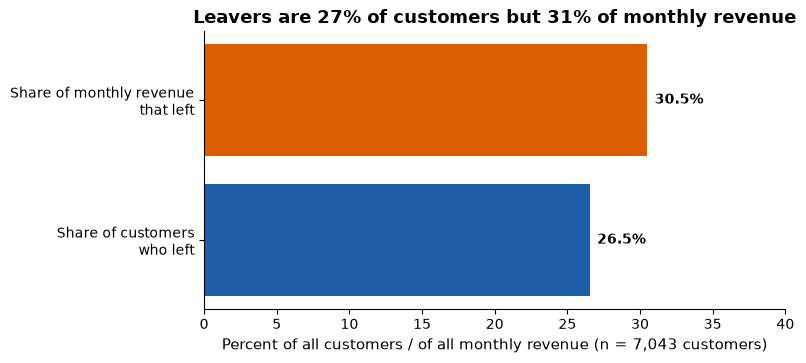

In [7]:
N = len(df); n_churn = int(df.churn_flag.sum()); base_rate = df.churn_flag.mean()
mrr_all = df.MonthlyCharges.sum(); mrr_lost = df.loc[df.churn_flag == 1, "MonthlyCharges"].sum()
avg_ch = df.loc[df.churn_flag == 1, "MonthlyCharges"].mean(); avg_st = df.loc[df.churn_flag == 0, "MonthlyCharges"].mean()
med_ch = df.loc[df.churn_flag == 1, "MonthlyCharges"].median(); med_st = df.loc[df.churn_flag == 0, "MonthlyCharges"].median()
one_pt_customers = N * 0.01
one_pt_mrr = one_pt_customers * avg_ch
tgt = pd.DataFrame({"measure": ["Customers", "Churned customers", "Churn rate (% of customers)", "Total monthly revenue (all customers)",
    "Monthly revenue of churned customers", "Share of monthly revenue lost (% of total)", "Annualised revenue of churned customers",
    "Average monthly bill, churned", "Average monthly bill, stayed", "Median monthly bill, churned", "Median monthly bill, stayed",
    "Monthly revenue per 1 point of churn (70 customers x avg churned bill)"],
  "value": [f"{N:,}", f"{n_churn:,}", f"{100*base_rate:.1f}%", f"${mrr_all:,.0f}", f"${mrr_lost:,.0f}", f"{100*mrr_lost/mrr_all:.1f}%",
            f"${12*mrr_lost:,.0f}", f"${avg_ch:,.2f}", f"${avg_st:,.2f}", f"${med_ch:,.2f}", f"${med_st:,.2f}", f"${one_pt_mrr:,.0f} per month (${12*one_pt_mrr:,.0f} per year)"]})
display(tgt)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
vals = [100*base_rate, 100*mrr_lost/mrr_all]
b = ax.barh(["Share of customers\nwho left", "Share of monthly revenue\nthat left"], vals, color=[BLUE, ORANGE])
for r, v in zip(b, vals): ax.text(v + 0.5, r.get_y() + r.get_height()/2, f"{v:.1f}%", va="center", fontweight="bold")
ax.set_xlim(0, 40); ax.set_xlabel("Percent of all customers / of all monthly revenue (n = 7,043 customers)")
ax.set_title(f"Leavers are {100*base_rate:.0f}% of customers but {100*mrr_lost/mrr_all:.0f}% of monthly revenue")
U.save(fig, CH / "01_target_customers_vs_revenue.png"); plt.show()


**What the output shows.**

| Measure | Value |
|---|---|
| Churn rate | 26.5% (1,869 of 7,043 customers) |
| Monthly revenue lost | $139,131 of $456,117 (30.5%) |
| Annualised | $1,669,570 |
| Average bill, leavers vs stayers | $74.44 vs $61.27 |
| Value of 1 point of churn (70 customers) | about $5,243 a month ($62,915 a year) |

Leavers cost more than their head count: they are 26.5% of customers but 30.5% of revenue, because they pay more. "Churn" here means the customer left within the observation window. Revenue is monthly billing only; margin and lifetime value are not in the data.

### 5.1 Hypothesis pre-registration table
**What this step does.** It writes down ten testable statements, the test for each, and the bar for "reliable", **before** we look at churn by group in section 6. Writing the plan first stops us picking the tests that happen to look good.

| Part | Explanation |
|---|---|
| Why this method | Run enough tests and some will look striking by luck. A fixed plan limits that. |
| Alternatives | Testing only after seeing charts. That is allowed for generating ideas, not for judging them. One combined test across all columns: it would say that something differs but not which statement holds. |
| How it works | Ten tests means ten chances for a false alarm. We apply the **Bonferroni rule** (divide the usual 5% error allowance by the number of tests): `alpha = 0.05 / 10 = 0.005`. A result counts as **reliable** only if its p-value is below 0.005 **and** its 95% interval for the difference excludes zero. |
| How to read it | The "predicted direction" column is our guess made now. Section 7 reports whether the data agreed. |

**Terms used in the table.** *Odds* = leavers divided by stayers in a group (30 leavers and 70 stayers give odds of 0.43). *Odds ratio* = odds in one group divided by odds in another. *Stratum* = one slice of the data held fixed (here one internet type). *phi* = the strength of a 2-group link on a 0 to 1 scale.

**What a p-value is, in one line.** The chance of seeing a gap this big if the two groups really left at the same rate. Small means the gap is unlikely to be luck.
**What we already knew.** We have seen the column names and general facts about telecom churn, not the group rates. The data used here is the same data that suggested these ideas, so a pass is evidence, not proof on fresh data.

| ID | Statement (plain words) | Predicted direction | Test and why | Interval method and why | Reliable if | Effect size and why |
|---|---|---|---|---|---|---|
| H1 | Month-to-month customers leave more often than customers on one- or two-year contracts | month-to-month higher | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | p < 0.005 and interval excludes 0 | phi, plus gap in points: phi (0 to 1; about 0.1 small, 0.3 medium) compares across tests, points are what a manager can price |
| H2 | Fiber-optic customers leave more often than DSL customers | fiber higher | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | p < 0.005 and interval excludes 0 | phi, plus gap in points: phi (0 to 1; about 0.1 small, 0.3 medium) compares across tests, points are what a manager can price |
| H3 | Customers in their first 12 months leave more often than those with longer tenure | first-year higher | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | p < 0.005 and interval excludes 0 | phi, plus gap in points: phi (0 to 1; about 0.1 small, 0.3 medium) compares across tests, points are what a manager can price |
| H4 | Customers paying by electronic check leave more often than those paying any other way | e-check higher | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | p < 0.005 and interval excludes 0 | phi, plus gap in points: phi (0 to 1; about 0.1 small, 0.3 medium) compares across tests, points are what a manager can price |
| H5 | Among internet customers, those without tech support leave more often than those with it | no tech support higher | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | p < 0.005 and interval excludes 0 | phi, plus gap in points: phi (0 to 1; about 0.1 small, 0.3 medium) compares across tests, points are what a manager can price |
| H6 | Customers who left pay a higher monthly bill than customers who stayed | churners pay more | Mann-Whitney: compares which group tends to have bigger values; bills are skewed, so no averages needed | bootstrap interval on the gap in medians: median is not pulled by a few high bills | p < 0.005 and interval excludes 0 | common-language effect: chance a random leaver pays more than a random stayer (50% = no difference); reads as a plain chance |
| H7 | Senior citizens leave more often than others | seniors higher | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | p < 0.005 and interval excludes 0 | phi, plus gap in points: phi (0 to 1; about 0.1 small, 0.3 medium) compares across tests, points are what a manager can price |
| H8 | Men and women leave at different rates | no difference expected | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | gap not reliable (we expect this) | phi, plus gap in points: a phi near 0 shows how small the gap is, not only that it is unreliable |
| H9 | The month-to-month penalty holds inside each internet type, not only because of fiber | penalty in DSL, fiber and no internet | Mantel-Haenszel: pools the contract effect across internet types so fiber cannot explain it away | Mantel-Haenszel 95% interval on the pooled odds ratio: the standard interval for this test | pooled p < 0.005, interval excludes 1, same direction in every type | pooled odds ratio (odds = leavers / stayers; ratio of the two groups' odds; 1 = no effect): one number across the three internet types |
| H10 | Having phone service changes the churn rate | no difference expected | chi-square on two groups: two groups, a yes/no outcome, so it asks whether the two rates differ by more than luck | bootstrap 95% interval on the gap: needs no assumption about the shape of the data | gap not reliable (we expect this) | phi, plus gap in points: a phi near 0 shows how small the gap is, not only that it is unreliable |

In [8]:
PREREG = pd.DataFrame([
 ("H1","Month-to-month leave more often than 1-2 year contracts","month-to-month higher"),
 ("H2","Fiber-optic leave more often than DSL","fiber higher"),
 ("H3","First 12 months leave more often than longer tenure","first-year higher"),
 ("H4","Electronic-check payers leave more often than others","e-check higher"),
 ("H5","Internet customers without tech support leave more often than with","no tech support higher"),
 ("H6","Leavers pay a higher monthly bill than stayers","churners pay more"),
 ("H7","Senior citizens leave more often than others","seniors higher"),
 ("H8","Men and women leave at different rates","no difference expected"),
 ("H9","Month-to-month penalty holds inside every internet type","holds in DSL, fiber, no internet"),
 ("H10","Phone service changes the churn rate","no difference expected")], columns=["id","statement","predicted_direction"])
TEST = {k: ("Mann-Whitney test + bootstrap interval on the gap in medians" if k == "H6" else "Mantel-Haenszel pooled test across internet types" if k == "H9" else "chi-square on two groups + bootstrap 95% interval on the gap") for k in PREREG.id}
EFFECT_WHY = {k: v for k, v in {'H1': 'phi, plus the gap in points. Phi (0 to 1; about 0.1 small, 0.3 medium) can be compared across tests; points are what a manager can price.', 'H2': 'phi, plus the gap in points. Same reason as H1.', 'H3': 'phi, plus the gap in points. Same reason as H1.', 'H4': 'phi, plus the gap in points. Same reason as H1.', 'H5': 'phi, plus the gap in points. Same reason as H1.', 'H6': 'common-language effect (chance a random leaver pays more than a random stayer; 50% = no difference). It needs no assumption about the shape of bills and reads as a plain chance.', 'H7': 'phi, plus the gap in points. Same reason as H1.', 'H8': 'phi, plus the gap in points. A phi near 0 shows how small the gap is, not only that it is unreliable.', 'H9': 'pooled odds ratio (odds = leavers divided by stayers; ratio = month-to-month odds over longer-contract odds; 1 = no effect). One number that summarises the contract effect across the three internet types.', 'H10': 'phi, plus the gap in points. Same reason as H8.'}.items()}
PREREG["test"] = PREREG.id.map(TEST); PREREG["effect_size_and_why"] = PREREG.id.map(EFFECT_WHY)
ALPHA = 0.05 / len(PREREG)
print("Number of hypotheses:", len(PREREG), "| Bonferroni alpha = 0.05 /", len(PREREG), "=", ALPHA)
display(PREREG)


Number of hypotheses: 10 | Bonferroni alpha = 0.05 / 10 = 0.005


,id,statement,predicted_direction,test,effect_size_and_why
0,H1,Month-to-month leave more often than 1-2 year ...,month-to-month higher,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. Phi (0 to 1; abou..."
1,H2,Fiber-optic leave more often than DSL,fiber higher,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. Same reason as H1."
2,H3,First 12 months leave more often than longer t...,first-year higher,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. Same reason as H1."
3,H4,Electronic-check payers leave more often than ...,e-check higher,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. Same reason as H1."
4,H5,Internet customers without tech support leave ...,no tech support higher,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. Same reason as H1."
5,H6,Leavers pay a higher monthly bill than stayers,churners pay more,Mann-Whitney test + bootstrap interval on the ...,common-language effect (chance a random leaver...
6,H7,Senior citizens leave more often than others,seniors higher,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. Same reason as H1."
7,H8,Men and women leave at different rates,no difference expected,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. A phi near 0 show..."
8,H9,Month-to-month penalty holds inside every inte...,"holds in DSL, fiber, no internet",Mantel-Haenszel pooled test across internet types,pooled odds ratio (odds = leavers divided by s...
9,H10,Phone service changes the churn rate,no difference expected,chi-square on two groups + bootstrap 95% inter...,"phi, plus the gap in points. Same reason as H8."


**What the output shows.** Ten hypotheses are fixed, with a stricter bar of p < 0.005 (0.05 divided by 10). They were written before section 6. Two (H8 gender, H10 phone service) predict **no** difference, so the plan can fail both ways.

## 6. Exploration
### 6.1 Churn by every category
**What this step does.** For each categorical column it computes, per category: customers, churned customers, churn rate, share of the base, share of all churners, lift versus the average, and monthly revenue lost.

| Part | Explanation |
|---|---|
| Why this method | A group table is the simplest honest way to compare groups. Anyone can check it by hand. |
| Alternatives | A regression (a fitted model). It adjusts groups for each other but is a model, which is out of scope here. We look at pairs of columns in 6.5 to deal with overlap. A decision tree: it finds splits by itself but is also a fitted model, out of scope. |
| How it works | `churn rate = churned / customers in the group`. `share of base = group customers / 7,043`. `share of churners = group churned / 1,869`. `lift = group rate / overall rate` (2.0 means twice the average). |
| How to read it | Lift above 1 means the group leaves more than average. A group with a high lift and a large share of the base matters most. |

**Strength ranking: Cramér's V.** `V = sqrt( chi-square / (n x (k - 1)) )`, where chi-square sums `(observed - expected)^2 / expected` over the cells of the column-by-outcome table, n is the customers and k is the smaller of the two table dimensions. It runs from 0 (no link) to 1 (perfect link). Rough guide: under 0.1 weak, 0.1 to 0.3 moderate, above 0.3 strong. Alternative: mutual information, which is harder to explain.

**Reading the p-values in this table.** They are descriptive: they are not corrected for comparing 16 columns and carry no interval. The pre-registered tests in section 7 carry the intervals and the stricter bar. Use V for ranking and the tests for decisions.

In [9]:
cat_all = ["gender","SeniorCitizen","Partner","Dependents","PhoneService","MultipleLines","InternetService","OnlineSecurity","OnlineBackup",
           "DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract","PaperlessBilling","PaymentMethod"]
tables = {c: U.rate_table(df, c) for c in cat_all}
rows = []
for c in cat_all:
    v, chi2, p, dof = U.cramers_v(df[c], df.churn_flag)
    tt = tables[c]
    rows.append(dict(column=c, cramers_v=round(v, 3), chi2=round(chi2, 1), p=fmt_p(p), highest_rate_category=tt.churn_rate_pct.idxmax(),
                     highest_rate_pct=tt.churn_rate_pct.max(), lowest_rate_category=tt.churn_rate_pct.idxmin(), lowest_rate_pct=tt.churn_rate_pct.min()))
rank = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
display(rank)
for c in cat_all:
    print(f"\n--- {c} ---"); display(tables[c])


,column,cramers_v,chi2,p,highest_rate_category,highest_rate_pct,lowest_rate_category,lowest_rate_pct
0,Contract,0.410,1184.6,below 0.0001,Month-to-month,42.71,Two year,2.83
1,InternetService,0.322,732.3,below 0.0001,Fiber optic,41.89,No,7.40
2,PaymentMethod,0.303,648.1,below 0.0001,Electronic check,45.29,Credit card (automatic),15.24
3,PaperlessBilling,0.192,259.2,below 0.0001,Yes,33.57,No,16.33
4,OnlineSecurity,0.171,206.5,below 0.0001,No,31.33,Yes,14.61
5,TechSupport,0.165,191.0,below 0.0001,No,31.19,Yes,15.17
6,Dependents,0.164,189.9,below 0.0001,No,31.28,Yes,15.45
7,SeniorCitizen,0.151,160.4,below 0.0001,1,41.68,0,23.61
8,Partner,0.150,159.4,below 0.0001,No,32.96,Yes,19.66
9,OnlineBackup,0.082,47.7,below 0.0001,No,29.17,Yes,21.53



--- gender ---


,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
gender,,,,,,,
Female,3488,939,26.92,49.52,50.24,1.01,70248.55
Male,3555,930,26.16,50.48,49.76,0.99,68882.30



--- SeniorCitizen ---


,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
SeniorCitizen,,,,,,,
0,5901,1393,23.61,83.79,74.53,0.89,100711.25
1,1142,476,41.68,16.21,25.47,1.57,38419.60


...

,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
Contract,,,,,,,
Month-to-month,3875,1655,42.71,55.02,88.55,1.61,120847.10
One year,1473,166,11.27,20.91,8.88,0.42,14118.45
Two year,1695,48,2.83,24.07,2.57,0.11,4165.30



--- PaperlessBilling ---


,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
PaperlessBilling,,,,,,,
No,2872,469,16.33,40.78,25.09,0.62,29620.85
Yes,4171,1400,33.57,59.22,74.91,1.26,109510.00



--- PaymentMethod ---


,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
PaymentMethod,,,,,,,
Bank transfer (automatic),1544,258,16.71,21.92,13.80,0.63,20091.90
Credit card (automatic),1522,232,15.24,21.61,12.41,0.57,17946.60
Electronic check,2365,1071,45.29,33.58,57.30,1.71,84288.75
Mailed check,1612,308,19.11,22.89,16.48,0.72,16803.60


**What the output shows.** Cramér's V ranks the 16 categorical columns.
- Strong: `Contract` (0.41).
- Moderate (0.1 to 0.3 in the guide, 0.32 and 0.30 here sit right at the edge): `InternetService` (0.32), `PaymentMethod` (0.30). Next come `PaperlessBilling` (0.19), `OnlineSecurity` (0.17), `TechSupport` (0.17), `Dependents` (0.16), `SeniorCitizen` (0.15), `Partner` (0.15).
- Weak: backup, device protection, streaming, multiple lines (0.04 to 0.08).
- No link: `PhoneService` (0.01) and `gender` (0.01).

Add-on tables (for example "TechSupport: No" at 31%) include customers with no internet, who leave at only 7.4%. That blurs the add-on effect. Section 6.4 repeats it for internet customers only.

### 6.2 One chart that ranks every category
**What this step does.** It puts the churn rate of every category of every column on one chart, sorted, with the company average as a reference line. Categories with fewer than 300 customers are marked, because small groups give shaky rates.

**Method.** Same rates as above, shown as horizontal bars. Alternatives: a table (harder to scan), or a dot plot with intervals (more precise, but with 36 categories harder for a non-technical reader). Read it by looking at the bars far to the right of the grey line (leave more) and far to the left (leave less).

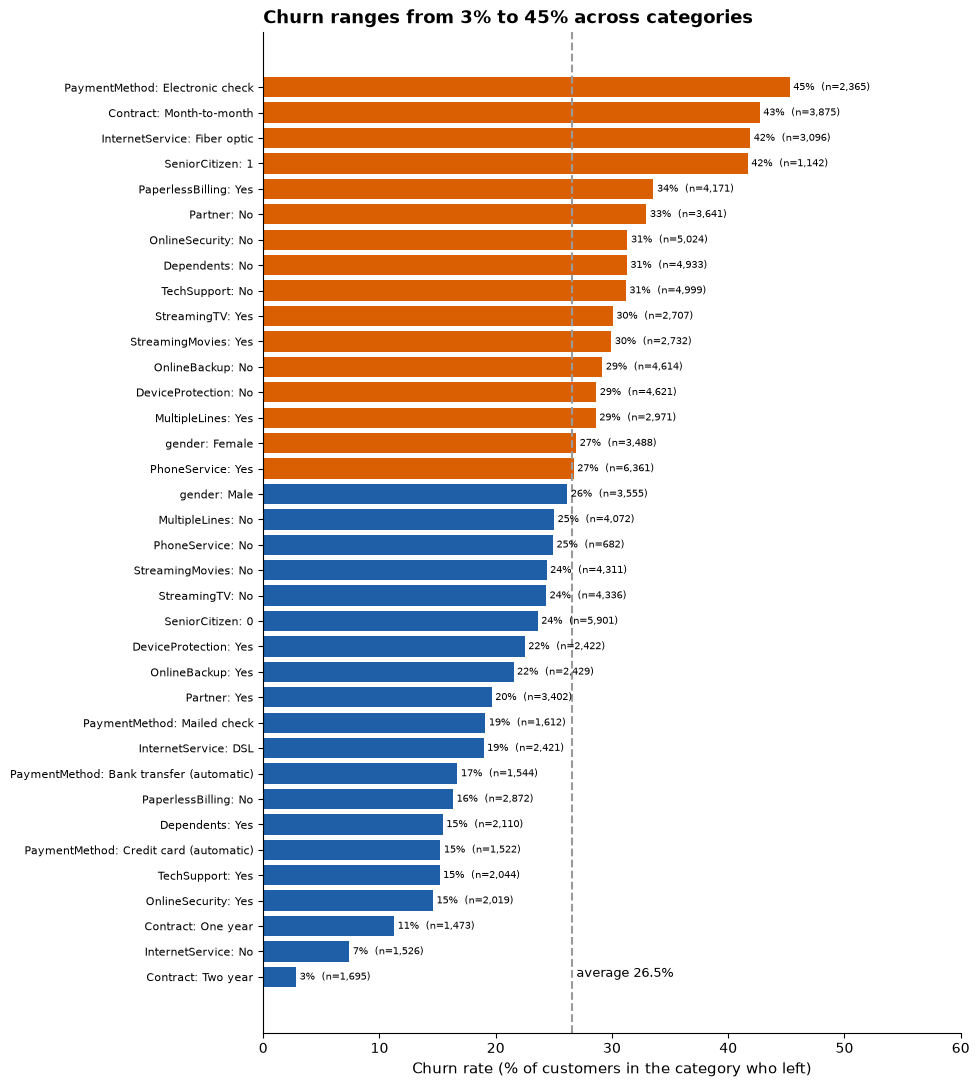

Categories under 300 customers: 0 of 36


In [10]:
long = []
for c in cat_all:
    for k, r in tables[c].iterrows():
        long.append(dict(label=f"{c}: {k}", rate=r.churn_rate_pct, n=int(r.customers)))
long = pd.DataFrame(long).sort_values("rate")
fig, ax = plt.subplots(figsize=(9, 13))
colors = [ORANGE if r > 100*base_rate else BLUE for r in long.rate]
ax.barh(long.label, long.rate, color=colors)
ax.axvline(100*base_rate, color=GREY, ls="--"); ax.text(100*base_rate + .4, 0, f"average {100*base_rate:.1f}%", color="black", fontsize=9)
for y, (r, n) in enumerate(zip(long.rate, long.n)):
    ax.text(r + .3, y, f"{r:.0f}%  (n={n:,})" + ("  small" if n < 300 else ""), va="center", fontsize=7.5)
ax.set_xlabel("Churn rate (% of customers in the category who left)"); ax.set_xlim(0, 60); ax.tick_params(axis="y", labelsize=8)
top = long.iloc[-1]; bot = long.iloc[0]
ax.set_title(f"Churn ranges from {bot.rate:.0f}% to {top.rate:.0f}% across categories", loc="left")
U.save(fig, CH / "02_churn_rate_all_categories.png"); plt.show()
print("Categories under 300 customers:", int((long.n < 300).sum()), "of", len(long))


**What the output shows.** Rates run from 3% (two-year contract) to 45% (electronic check). The top four orange bars are electronic check (45%), month-to-month (43%), fiber (42%) and senior citizens (42%). Gender and phone service sit on the average line. All 36 categories have at least 300 customers, so none is flagged as small.

### 6.3 Churn by the main drivers: contract, tenure, internet type, payment method, price
**What this step does.** It draws one chart each for the five columns with the strongest links, using the group tables above and the bands defined in section 4.

**Method.** Bar charts of group churn rate with customer counts. Alternatives: box plots of numeric columns (they hide the rate we care about), or a line through the bands (it implies a smooth climb that the data does not show). Bands are fixed in section 4 (not chosen to flatter the result). Read each bar as "of the customers in this group, this share left".

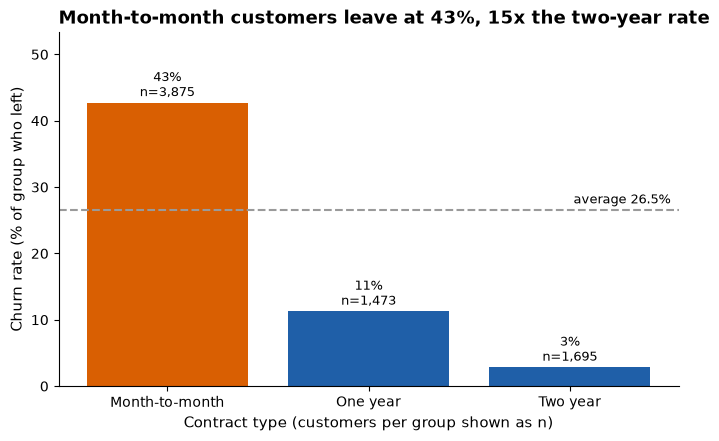

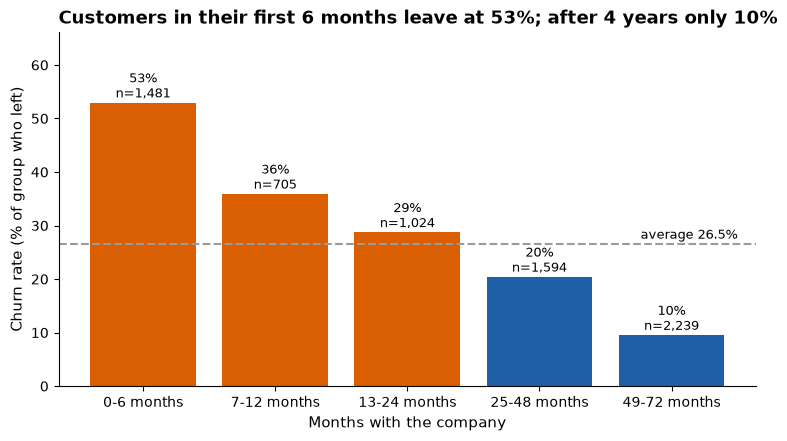

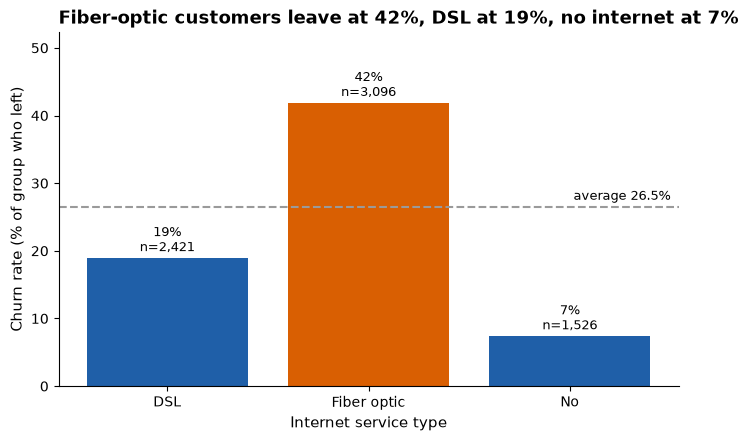

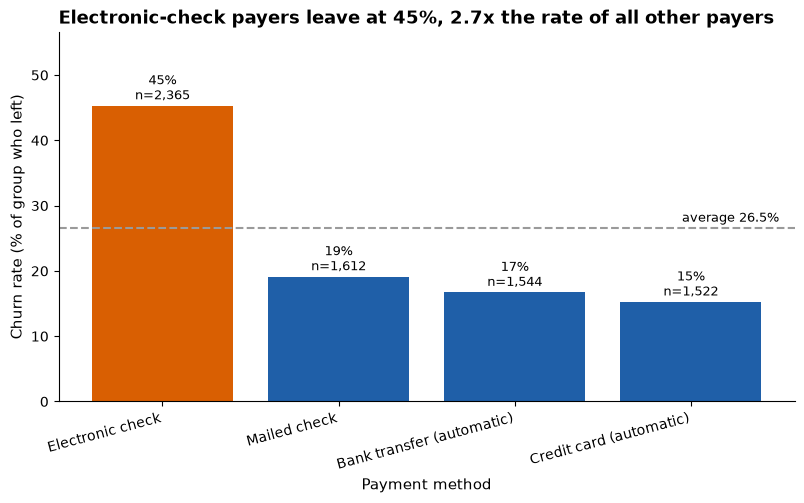

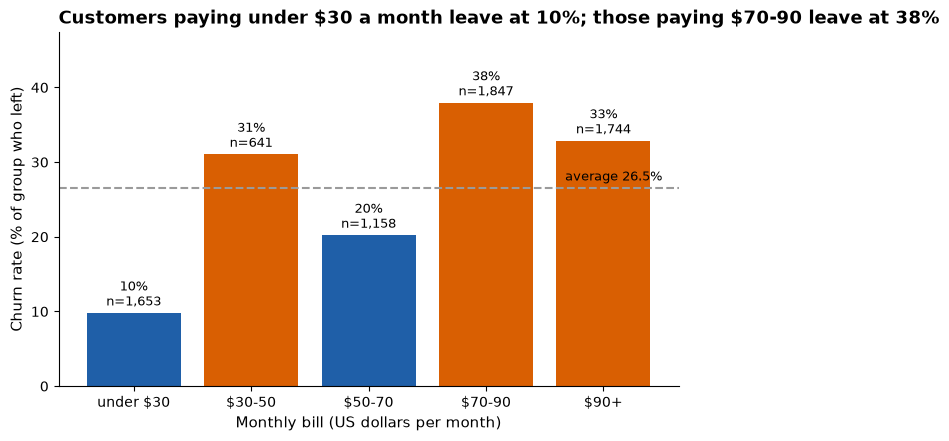

,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
tenure_band,,,,,,,
0-6 months,1481,784,52.94,21.03,41.95,1.99,49896.10
7-12 months,705,253,35.89,10.01,13.54,1.35,19058.15
13-24 months,1024,294,28.71,14.54,15.73,1.08,23081.65
25-48 months,1594,325,20.39,22.63,17.39,0.77,27462.50
49-72 months,2239,213,9.51,31.79,11.40,0.36,19632.45


,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
monthly_charge_band,,,,,,,
under $30,1653,162,9.80,23.47,8.67,0.37,3583.75
$30-50,641,199,31.05,9.10,10.65,1.17,8527.15
$50-70,1158,234,20.21,16.44,12.52,0.76,14038.95
$70-90,1847,701,37.95,26.22,37.51,1.43,55926.90
$90+,1744,573,32.86,24.76,30.66,1.24,57054.10


In [11]:
def bar_rate(tbl, title, xlabel, fname, order=None, figsize=(8, 4.6), rot=0):
    t_ = tbl.reindex(order) if order is not None else tbl
    fig, ax = plt.subplots(figsize=figsize)
    cols = [ORANGE if r > 100*base_rate else BLUE for r in t_.churn_rate_pct]
    bars = ax.bar(t_.index.astype(str), t_.churn_rate_pct, color=cols)
    ax.axhline(100*base_rate, color=GREY, ls="--"); ax.text(len(t_) - .5, 100*base_rate + 1, f"average {100*base_rate:.1f}%", ha="right", fontsize=9)
    for b_, (_, r) in zip(bars, t_.iterrows()):
        ax.text(b_.get_x() + b_.get_width()/2, r.churn_rate_pct + 1, f"{r.churn_rate_pct:.0f}%\nn={int(r.customers):,}", ha="center", fontsize=9)
    ax.set_ylim(0, max(t_.churn_rate_pct) * 1.25); ax.set_ylabel("Churn rate (% of group who left)"); ax.set_xlabel(xlabel)
    plt.setp(ax.get_xticklabels(), rotation=rot, ha="right" if rot else "center")
    ax.set_title(title, loc="left"); U.save(fig, CH / fname); plt.show()

ct = tables["Contract"]
bar_rate(ct, f"Month-to-month customers leave at {ct.loc['Month-to-month','churn_rate_pct']:.0f}%, {ct.loc['Month-to-month','churn_rate_pct']/ct.loc['Two year','churn_rate_pct']:.0f}x the two-year rate",
         "Contract type (customers per group shown as n)", "03_churn_by_contract.png", ["Month-to-month","One year","Two year"])
tn = U.rate_table(df, "tenure_band", order=TB_ORDER)
bar_rate(tn, f"Customers in their first 6 months leave at {tn.loc['0-6 months','churn_rate_pct']:.0f}%; after 4 years only {tn.loc['49-72 months','churn_rate_pct']:.0f}%",
         "Months with the company", "04_churn_by_tenure.png", TB_ORDER, figsize=(9, 4.6))
it = tables["InternetService"]
bar_rate(it, f"Fiber-optic customers leave at {it.loc['Fiber optic','churn_rate_pct']:.0f}%, DSL at {it.loc['DSL','churn_rate_pct']:.0f}%, no internet at {it.loc['No','churn_rate_pct']:.0f}%",
         "Internet service type", "05_churn_by_internet.png", ["DSL","Fiber optic","No"])
pm = tables["PaymentMethod"]
bar_rate(pm, f"Electronic-check payers leave at {pm.loc['Electronic check','churn_rate_pct']:.0f}%, {pm.loc['Electronic check','churn_rate_pct']/(100*df[df.PaymentMethod!='Electronic check'].churn_flag.mean()):.1f}x the rate of all other payers",
         "Payment method", "06_churn_by_payment.png", ["Electronic check","Mailed check","Bank transfer (automatic)","Credit card (automatic)"], figsize=(9.5, 4.8), rot=15)
mc = U.rate_table(df, "monthly_charge_band", order=CB_ORDER)
bar_rate(mc, f"Customers paying under $30 a month leave at {mc.loc['under $30','churn_rate_pct']:.0f}%; those paying $70-90 leave at {mc.loc['$70-90','churn_rate_pct']:.0f}%",
         "Monthly bill (US dollars per month)", "07_churn_by_monthly_charge.png", CB_ORDER)
display(tn); display(mc)


**What the output shows.**
- Contract: month-to-month 42.7%, one year 11.3%, two year 2.8%.
- Tenure: 52.9% in months 0-6, falling to 9.5% after 48 months.
- Internet: fiber 41.9%, DSL 19.0%, none 7.4%.
- Payment: electronic check 45.3%; the other three 15.2% to 19.1%.
- Monthly bill: 9.8% under $30, 37.9% at $70-90, 32.9% at $90+. The curve is not a straight climb, because $30-50 (31.1%) is higher than $50-70 (20.2%).

### 6.4 Add-on services
**What this step does.** It compares churn for customers with and without each add-on, **among internet customers only** (5,517 of 7,043). Customers without internet cannot have the add-ons, so including them would mix two groups.

**Method.** Same rate formula as 6.1, restricted to `has_internet = 1`. Alternatives: use all customers (it wrongly blends "no internet" into "no add-on"), or compare by add-on count only (it hides which add-on matters). Read each pair of bars as "with versus without".

customers         churn_rate_pct      
has_it                  No     Yes             No   Yes
addon                                                  
DeviceProtection    3095.0  2422.0           39.1  22.5
OnlineBackup        3088.0  2429.0           39.9  21.5
OnlineSecurity      3498.0  2019.0           41.8  14.6
StreamingMovies     2785.0  2732.0           33.7  29.9
StreamingTV         2810.0  2707.0           33.5  30.1
TechSupport         3473.0  2044.0           41.6  15.2

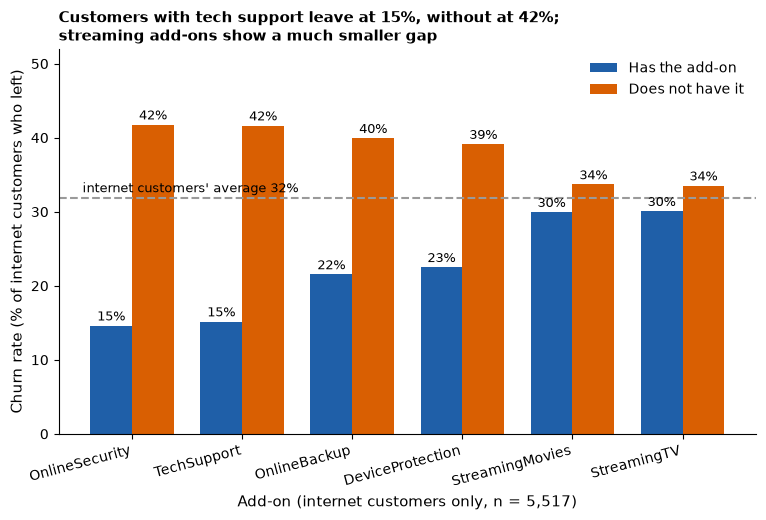

,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,lift_vs_avg,monthly_rev_lost_usd
n_protection_addons,,,,,,,
0,1267,718,56.67,22.97,40.89,1.78,50806.05
1,1467,570,38.85,26.59,32.46,1.22,44465.15
2,1372,326,23.76,24.87,18.56,0.75,28377.70
3,941,117,12.43,17.06,6.66,0.39,10723.60
4,470,25,5.32,8.52,1.42,0.17,2456.75


In [12]:
inet = df[df.has_internet == 1]
rows = []
for c in addons:
    for lvl in ["Yes", "No"]:
        s = inet[inet[c] == lvl]
        rows.append(dict(addon=c, has_it=lvl, customers=len(s), churn_rate_pct=100*s.churn_flag.mean()))
ad = pd.DataFrame(rows)
inet_rate = 100*inet.churn_flag.mean()
display(ad.pivot(index="addon", columns="has_it", values=["customers","churn_rate_pct"]).round(1))
order_ad = ad[ad.has_it == "Yes"].sort_values("churn_rate_pct").addon.tolist()
fig, ax = plt.subplots(figsize=(9, 5))
w = .38; x = np.arange(len(order_ad))
yes = [ad[(ad.addon == a) & (ad.has_it == "Yes")].churn_rate_pct.iloc[0] for a in order_ad]
no = [ad[(ad.addon == a) & (ad.has_it == "No")].churn_rate_pct.iloc[0] for a in order_ad]
ax.bar(x - w/2, yes, w, color=BLUE, label="Has the add-on"); ax.bar(x + w/2, no, w, color=ORANGE, label="Does not have it")
for i, (a_, b_) in enumerate(zip(yes, no)):
    ax.text(i - w/2, a_ + .7, f"{a_:.0f}%", ha="center", fontsize=9); ax.text(i + w/2, b_ + .7, f"{b_:.0f}%", ha="center", fontsize=9)
ax.axhline(inet_rate, color=GREY, ls="--"); ax.text(-.45, inet_rate + .8, f"internet customers' average {inet_rate:.0f}%", ha="left", fontsize=9)
ax.set_ylim(0, 52); ax.set_xticks(x); ax.set_xticklabels(order_ad, rotation=15, ha="right"); ax.set_ylabel("Churn rate (% of internet customers who left)")
ax.set_xlabel("Add-on (internet customers only, n = %s)" % f"{len(inet):,}"); ax.legend(frameon=False, loc="upper right")
sec = ad[(ad.addon == "TechSupport")]
ax.set_title(f"Customers with tech support leave at {sec[sec.has_it=='Yes'].churn_rate_pct.iloc[0]:.0f}%, without at {sec[sec.has_it=='No'].churn_rate_pct.iloc[0]:.0f}%;\nstreaming add-ons show a much smaller gap", loc="left", fontsize=11)
U.save(fig, CH / "08_churn_by_addon.png"); plt.show()
cnt = U.rate_table(inet, "n_protection_addons"); display(cnt)


**What the output shows.** Among 5,517 internet customers (average churn 31.9%):
- With security: 14.6%, without: 41.8%. With tech support: 15.2%, without: 41.6%.
- Backup and device protection: 22% against about 40% and 39%.
- Streaming: customers with it leave slightly less (30% against 34% without it). The gap is under 4 points, small next to the protection add-ons. (In the all-customer tables of 6.1, streaming looks worse only because customers with no internet are counted as 'No'.)
- The number of protection add-ons shows a steady slope: 0 add-ons 56.7%, 1: 38.9%, 2: 23.8%, 3: 12.4%, 4: 5.3%. Customers who choose add-ons may differ in other ways, so this is a link and not proof of an effect.

### 6.5 The strongest two-way combinations
**What this step does.** It crosses two columns at a time and shows the churn rate in each cell, with the customer count. We pick four crossings built from the strongest columns in 6.1: contract by internet type, tenure by contract, payment method by contract, and tech support by internet type.

| Part | Explanation |
|---|---|
| Why this method | Contract, tenure, price and internet type overlap. Crossing them shows whether a group is risky on its own or only because it is mixed with another risky group. |
| Alternatives | A regression, which does this adjustment with a formula but is a model. A cross-table needs no assumptions. Three-way tables: more detail, but cells shrink below 100 customers. |
| How it works | For each cell: `rate = churned in cell / customers in cell`. Cells under 100 customers carry an asterisk because one customer moves the rate by 1 point or more. |
| How to read it | Compare down a column to see the effect of one variable while the other is held fixed. Darker orange means more churn. |

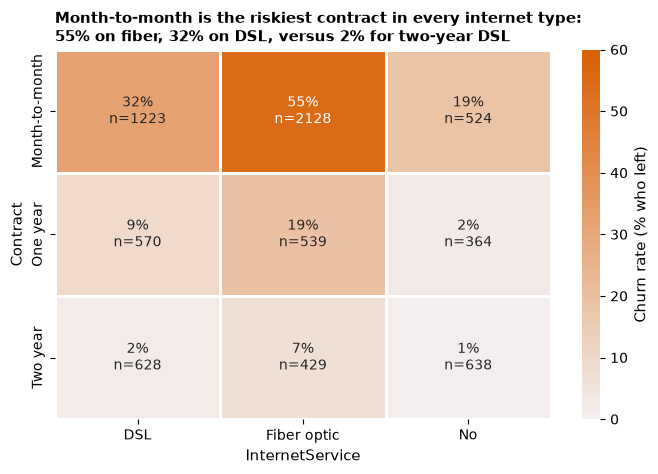

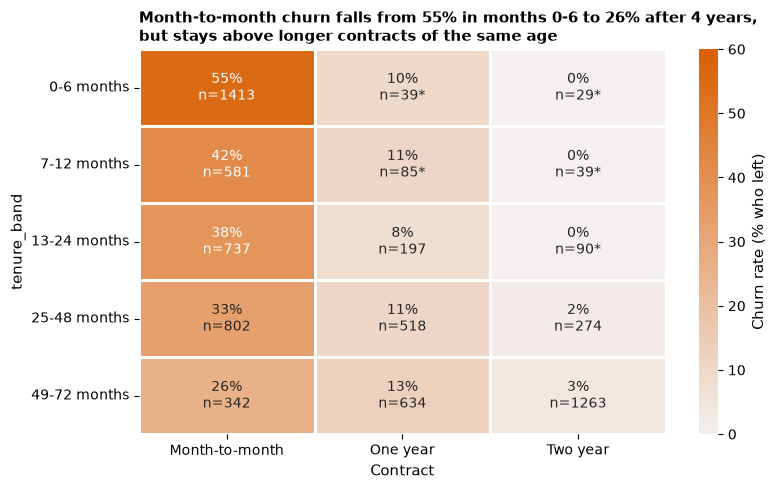

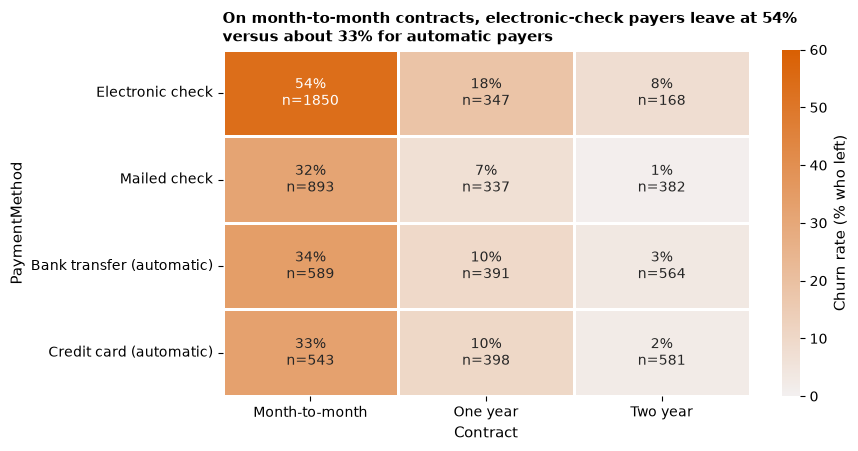

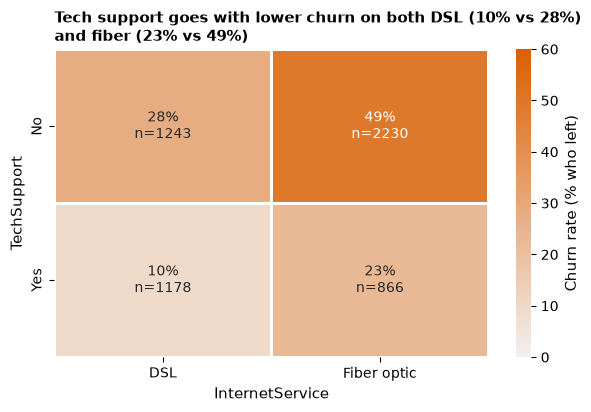

contract x internet | cells under 100 customers: 0 of 9
tenure band x contract | cells under 100 customers: 5 of 15
payment x contract | cells under 100 customers: 0 of 12
tech support x internet | cells under 100 customers: 0 of 4


In [13]:
def heat_tables(rowc, colc, row_order=None, col_order=None, data=None):
    d = df if data is None else data
    p = d.pivot_table(index=rowc, columns=colc, values="churn_flag", aggfunc="mean") * 100
    n = d.pivot_table(index=rowc, columns=colc, values="churn_flag", aggfunc="size")
    if row_order: p, n = p.reindex(row_order), n.reindex(row_order)
    if col_order: p, n = p[col_order], n[col_order]
    return p, n

def heat(rowc, colc, title, fname, row_order=None, col_order=None, data=None, figsize=(8, 4.8)):
    p, n = heat_tables(rowc, colc, row_order, col_order, data)
    ann = p.round(0).astype("Int64").astype(str) + "%\nn=" + n.astype("Int64").astype(str) + np.where(n < 100, "*", "")
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(p, annot=ann, fmt="", cmap=sns.light_palette(ORANGE, as_cmap=True), vmin=0, vmax=60,
                cbar_kws={"label": "Churn rate (% who left)"}, ax=ax, linewidths=1, linecolor="white")
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel(colc); ax.set_ylabel(rowc)
    U.save(fig, CH / fname); plt.show(); return p, n

CT_ORD = ["Month-to-month", "One year", "Two year"]
p1, n1 = heat_tables("Contract", "InternetService", CT_ORD, ["DSL", "Fiber optic", "No"])
assert (p1.loc["Month-to-month"] > p1.loc["One year"]).all() and (p1.loc["One year"] >= p1.loc["Two year"]).all()
mtm_f = p1.loc["Month-to-month", "Fiber optic"]; mtm_d = p1.loc["Month-to-month", "DSL"]; two_d = p1.loc["Two year", "DSL"]
p1, n1 = heat("Contract", "InternetService",
  f"Month-to-month is the riskiest contract in every internet type:\n{mtm_f:.0f}% on fiber, {mtm_d:.0f}% on DSL, versus {two_d:.0f}% for two-year DSL",
  "10_heat_contract_by_internet.png", CT_ORD, ["DSL", "Fiber optic", "No"])
p2, n2 = heat_tables("tenure_band", "Contract", TB_ORDER, CT_ORD)
m_first = p2.loc["0-6 months", "Month-to-month"]; m_late = p2.loc["49-72 months", "Month-to-month"]
p2, n2 = heat("tenure_band", "Contract",
  f"Month-to-month churn falls from {m_first:.0f}% in months 0-6 to {m_late:.0f}% after 4 years,\nbut stays above longer contracts of the same age",
  "11_heat_tenure_by_contract.png", TB_ORDER, CT_ORD, figsize=(8.5, 5))
PM_ORD = ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]
p3, n3 = heat_tables("PaymentMethod", "Contract", PM_ORD, CT_ORD)
e_m = p3.loc["Electronic check", "Month-to-month"]; a_m = p3.loc[["Bank transfer (automatic)", "Credit card (automatic)"], "Month-to-month"].mean()
p3, n3 = heat("PaymentMethod", "Contract",
  f"On month-to-month contracts, electronic-check payers leave at {e_m:.0f}%\nversus about {a_m:.0f}% for automatic payers",
  "12_heat_payment_by_contract.png", PM_ORD, CT_ORD, figsize=(8.5, 4.5))
p4, n4 = heat_tables("TechSupport", "InternetService", ["No", "Yes"], ["DSL", "Fiber optic"], data=inet)
p4, n4 = heat("TechSupport", "InternetService",
  f"Tech support goes with lower churn on both DSL ({p4.loc['Yes','DSL']:.0f}% vs {p4.loc['No','DSL']:.0f}%)\nand fiber ({p4.loc['Yes','Fiber optic']:.0f}% vs {p4.loc['No','Fiber optic']:.0f}%)",
  "13_heat_techsupport_by_internet.png", ["No", "Yes"], ["DSL", "Fiber optic"], data=inet, figsize=(7, 4))
for nm, pp, nn in [("contract x internet", p1, n1), ("tenure band x contract", p2, n2), ("payment x contract", p3, n3), ("tech support x internet", p4, n4)]:
    print(nm, "| cells under 100 customers:", int((nn < 100).sum().sum()), "of", nn.size)


**What the output shows.**
- Contract x internet: month-to-month is highest in every internet type (fiber 55%, DSL 32%, none 19%); two-year DSL is 2%. All 9 cells have 100+ customers.
- Tenure x contract: month-to-month falls from 55% (months 0-6) to 26% (after 4 years) but stays above the one-year and two-year columns at every age. 5 of 15 cells have under 100 customers (marked *), so the 0% cells for two-year are noise-prone.
- Payment x contract: inside month-to-month, electronic check is about 54% against about 33% for automatic payers.
- Tech support x internet: tech support goes with lower churn on both DSL and fiber, so it is not only a fiber effect.

### 6.6 How churn concentrates, and what a small intervention could reach
**What this step does.** It splits customers into 17 observed segments (contract x internet type x tenure up to 12 months or longer; 3 x 3 x 2 = 18 are possible, but no customer is on a two-year contract with fiber in the first 12 months, so that cell is empty), ranks the segments from highest to lowest churn rate, and shows how much of the churn and the lost revenue sits in the first few segments. It then sizes a handful of simple, targetable groups.

| Part | Explanation |
|---|---|
| Why this method | The question is "where should a retention budget go first". A concentration (gains) curve answers it without a model. |
| Alternatives | Rank customers by a fitted risk score. That is the model builder's job, and it would be graded on the same data it learned from. A single cut-off on one column (contract only): simpler, but it ignores that tenure and internet type sharpen the targeting. |
| How it works | Order segments by churn rate, highest first. Plot `cumulative share of customers` (x) against `cumulative share of churners` (y). A diagonal line means churn is spread evenly. The higher the curve above the diagonal, the more concentrated churn is. We do the same for lost monthly revenue. |
| How to read it | If the first 20% of customers hold 45% of churners, the curve is at 45 when x = 20. |

**Caution.** The segment ranking is built and read on the same customers, so it is slightly optimistic. Unclear how much from this data, because there is no second sample.

,customers,churned,churn_rate_pct,share_of_base_pct,share_of_churners_pct,monthly_rev_lost_usd,cum_share_customers_pct,cum_share_churners_pct,cum_share_rev_lost_pct
segment,,,,,,,,,
Month-to-month | Fiber optic | tenure 0-12,916,643,70.2,13.0,34.4,53178.3,13.0,34.4,38.2
Month-to-month | Fiber optic | tenure 13+,1212,519,42.8,17.2,27.8,47303.7,30.2,62.2,72.2
Month-to-month | DSL | tenure 0-12,690,293,42.5,9.8,15.7,13351.9,40.0,77.8,81.8
One year | Fiber optic | tenure 0-12,7,2,28.6,0.1,0.1,201.2,40.1,78.0,82.0
Month-to-month | No | tenure 0-12,388,88,22.7,5.5,4.7,1771.2,45.6,82.7,83.2
One year | Fiber optic | tenure 13+,532,102,19.2,7.6,5.5,10370.8,53.2,88.1,90.7
Month-to-month | DSL | tenure 13+,533,101,19.0,7.6,5.4,5015.4,60.7,93.5,94.3
One year | DSL | tenure 0-12,42,7,16.7,0.6,0.4,373.0,61.4,93.9,94.6
One year | DSL | tenure 13+,528,46,8.7,7.5,2.5,2983.3,68.8,96.4,96.7


Segments with fewer than 100 customers: ['One year | Fiber optic | tenure 0-12', 'One year | DSL | tenure 0-12', 'One year | No | tenure 0-12', 'Two year | DSL | tenure 0-12', 'Two year | No | tenure 0-12']


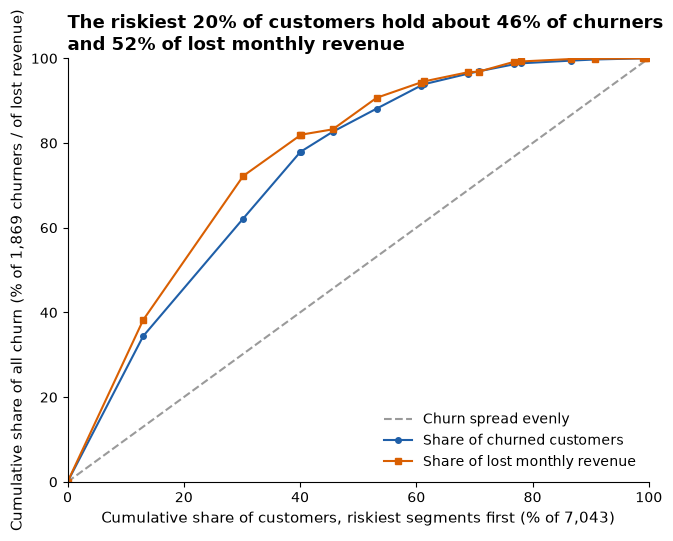

,group,customers,share_of_base_pct,churn_rate_pct,churned,share_of_all_churners_pct,monthly_rev_lost_usd,share_of_lost_rev_pct
0,Month-to-month (any),3875,55.0,42.7,1655,88.6,120847.1,86.9
1,"Month-to-month, first 12 months",1994,28.3,51.4,1024,54.8,68301.4,49.1
2,Month-to-month on fiber,2128,30.2,54.6,1162,62.2,100482.0,72.2
3,"Month-to-month on fiber, first 12 months",916,13.0,70.2,643,34.4,53178.3,38.2
4,"Month-to-month, electronic check",1850,26.3,53.7,994,53.2,77315.6,55.6
5,"Month-to-month, fiber, electronic check",1307,18.6,60.4,789,42.2,68281.5,49.1
6,"Month-to-month, fiber, no tech support",1796,25.5,57.5,1033,55.3,88165.8,63.4


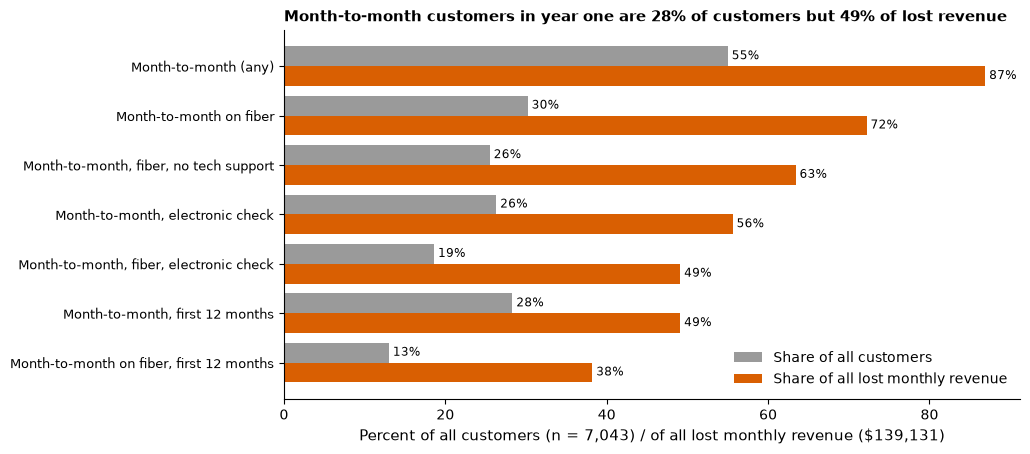

In [14]:
df["segment"] = df.Contract + " | " + df.InternetService + " | " + np.where(df.tenure <= 12, "tenure 0-12", "tenure 13+")
seg = U.rate_table(df, "segment").sort_values("churn_rate_pct", ascending=False)
seg["cum_share_customers_pct"] = seg.share_of_base_pct.cumsum()
seg["cum_share_churners_pct"] = seg.share_of_churners_pct.cumsum()
seg["share_of_rev_lost_pct"] = 100 * seg.monthly_rev_lost_usd / mrr_lost
seg["cum_share_rev_lost_pct"] = seg.share_of_rev_lost_pct.cumsum()
display(seg[["customers","churned","churn_rate_pct","share_of_base_pct","share_of_churners_pct","monthly_rev_lost_usd","cum_share_customers_pct","cum_share_churners_pct","cum_share_rev_lost_pct"]].round(1))
print("Segments with fewer than 100 customers:", seg[seg.customers < 100].index.tolist())

def cum_at(share):  # interpolate cumulative share of churners and revenue at a given share of customers
    xs = np.r_[0, seg.cum_share_customers_pct.values]
    return (np.interp(share, xs, np.r_[0, seg.cum_share_churners_pct.values]), np.interp(share, xs, np.r_[0, seg.cum_share_rev_lost_pct.values]))
conc20 = cum_at(20); conc30 = cum_at(30)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot([0, 100], [0, 100], color=GREY, ls="--", label="Churn spread evenly")
ax.plot(np.r_[0, seg.cum_share_customers_pct], np.r_[0, seg.cum_share_churners_pct], color=BLUE, marker="o", ms=4, label="Share of churned customers")
ax.plot(np.r_[0, seg.cum_share_customers_pct], np.r_[0, seg.cum_share_rev_lost_pct], color=ORANGE, marker="s", ms=4, label="Share of lost monthly revenue")
ax.set_xlabel("Cumulative share of customers, riskiest segments first (% of 7,043)"); ax.set_ylabel("Cumulative share of all churn (% of 1,869 churners / of lost revenue)")
ax.legend(frameon=False, loc="lower right"); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title(f"The riskiest 20% of customers hold about {conc20[0]:.0f}% of churners\nand {conc20[1]:.0f}% of lost monthly revenue", loc="left")
U.save(fig, CH / "14_concentration_curve.png"); plt.show()

fiber = df.InternetService == "Fiber optic"; m2m = df.Contract == "Month-to-month"; new12 = df.tenure <= 12; echeck = df.PaymentMethod == "Electronic check"
cands = {
 "Month-to-month (any)": m2m,
 "Month-to-month, first 12 months": m2m & new12,
 "Month-to-month on fiber": m2m & fiber,
 "Month-to-month on fiber, first 12 months": m2m & fiber & new12,
 "Month-to-month, electronic check": m2m & echeck,
 "Month-to-month, fiber, electronic check": m2m & fiber & echeck,
 "Month-to-month, fiber, no tech support": m2m & fiber & (df.TechSupport == "No"),
}
rows = []
for k, m in cands.items():
    s = df[m]
    rows.append(dict(group=k, customers=len(s), share_of_base_pct=100*len(s)/N, churn_rate_pct=100*s.churn_flag.mean(), churned=int(s.churn_flag.sum()),
                     share_of_all_churners_pct=100*s.churn_flag.sum()/n_churn, monthly_rev_lost_usd=s.loc[s.churn_flag == 1, "MonthlyCharges"].sum(),
                     share_of_lost_rev_pct=100*s.loc[s.churn_flag == 1, "MonthlyCharges"].sum()/mrr_lost,
                     share_of_group_that_is_churner_pct=100*s.churn_flag.mean()))
cand = pd.DataFrame(rows).drop(columns="share_of_group_that_is_churner_pct").round(1)
cand["churners_per_100_customers_targeted"] = cand.churn_rate_pct
display(cand.drop(columns="churners_per_100_customers_targeted"))
fig, ax = plt.subplots(figsize=(9.5, 4.8))
c2 = cand.sort_values("share_of_lost_rev_pct")
y = np.arange(len(c2)); ax.barh(y + .2, c2.share_of_base_pct, .4, color=GREY, label="Share of all customers")
ax.barh(y - .2, c2.share_of_lost_rev_pct, .4, color=ORANGE, label="Share of all lost monthly revenue")
for i, (a_, b_) in enumerate(zip(c2.share_of_base_pct, c2.share_of_lost_rev_pct)):
    ax.text(a_ + .5, i + .2, f"{a_:.0f}%", va="center", fontsize=8.5); ax.text(b_ + .5, i - .2, f"{b_:.0f}%", va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(c2.group, fontsize=9); ax.set_xlabel("Percent of all customers (n = 7,043) / of all lost monthly revenue ($%s)" % f"{mrr_lost:,.0f}")
ax.legend(frameon=False, loc="lower right")
best = cand.set_index("group").loc["Month-to-month, first 12 months"]
ax.set_title(f"Month-to-month customers in year one are {best.share_of_base_pct:.0f}% of customers but {best.share_of_lost_rev_pct:.0f}% of lost revenue", loc="left", fontsize=11)
U.save(fig, CH / "15_candidate_groups_revenue.png"); plt.show()


**What the output shows.**
- 17 of the 18 possible segments are observed. The empty one is two-year contract, fiber, first 12 months: no customer is in it.
- Riskiest segment: month-to-month, fiber, first 12 months: 916 customers (13.0% of base), churn 70.2%, 34.4% of leavers, 38.2% of lost revenue.
- The riskiest 20% of customers hold about 46% of leavers and 52% of lost revenue. The riskiest 30%: about 62% and 72%.
- Candidate groups: month-to-month in year one is 28.3% of customers, 54.8% of leavers and 49.1% of lost revenue. Month-to-month on fiber is 30.2% of customers and 72.2% of lost revenue. The narrowest group (fiber, year one) reaches 34.4% of leavers by contacting 13.0%.
- Five tiny segments (under 100 customers) hold under 2% of customers; their rates are not reliable.

### 6.7 Correlations among numeric columns
**What this step does.** It measures how strongly the numeric columns move together, and how each moves with churn.

| Part | Explanation |
|---|---|
| Why this method | Two columns that move together carry the same information. The model builder needs to know which ones. |
| Alternatives | Scatter plots for every pair (hard to read at once); variance inflation factors (an overlap score that needs a fitted model first). |
| How it works | **Pearson correlation r** = `sum((x - mean x)(y - mean y)) / sqrt(sum((x - mean x)^2) x sum((y - mean y)^2))`. It runs from -1 to +1. **Spearman** is the same formula on ranks (1st, 2nd, 3rd...), so it also catches curved but steady links and ignores outliers. |
| How to read it | Near 0 means no link. Above 0.8 in size means the two columns are close to duplicates. Against `churn_flag`, a negative number means customers with higher values leave less. |

,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,n_addons,n_protection_addons,churn_flag
tenure,1.00,0.25,0.83,0.25,0.49,0.50,-0.35
MonthlyCharges,0.25,1.00,0.65,1.00,0.72,0.56,0.19
TotalCharges,0.83,0.65,1.00,0.65,0.75,0.68,-0.20
avg_monthly_spend,0.25,1.00,0.65,1.00,0.72,0.56,0.19
n_addons,0.49,0.72,0.75,0.72,1.00,0.91,-0.09
n_protection_addons,0.50,0.56,0.68,0.56,0.91,1.00,-0.17
churn_flag,-0.35,0.19,-0.20,0.19,-0.09,-0.17,1.00


,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,n_addons,n_protection_addons,churn_flag
tenure,1.00,0.28,0.89,0.27,0.47,0.48,-0.37
MonthlyCharges,0.28,1.00,0.64,0.99,0.74,0.58,0.18
TotalCharges,0.89,0.64,1.00,0.64,0.72,0.67,-0.23
avg_monthly_spend,0.27,0.99,0.64,1.00,0.74,0.58,0.18
n_addons,0.47,0.74,0.72,0.74,1.00,0.91,-0.06
n_protection_addons,0.48,0.58,0.67,0.58,0.91,1.00,-0.15
churn_flag,-0.37,0.18,-0.23,0.18,-0.06,-0.15,1.00


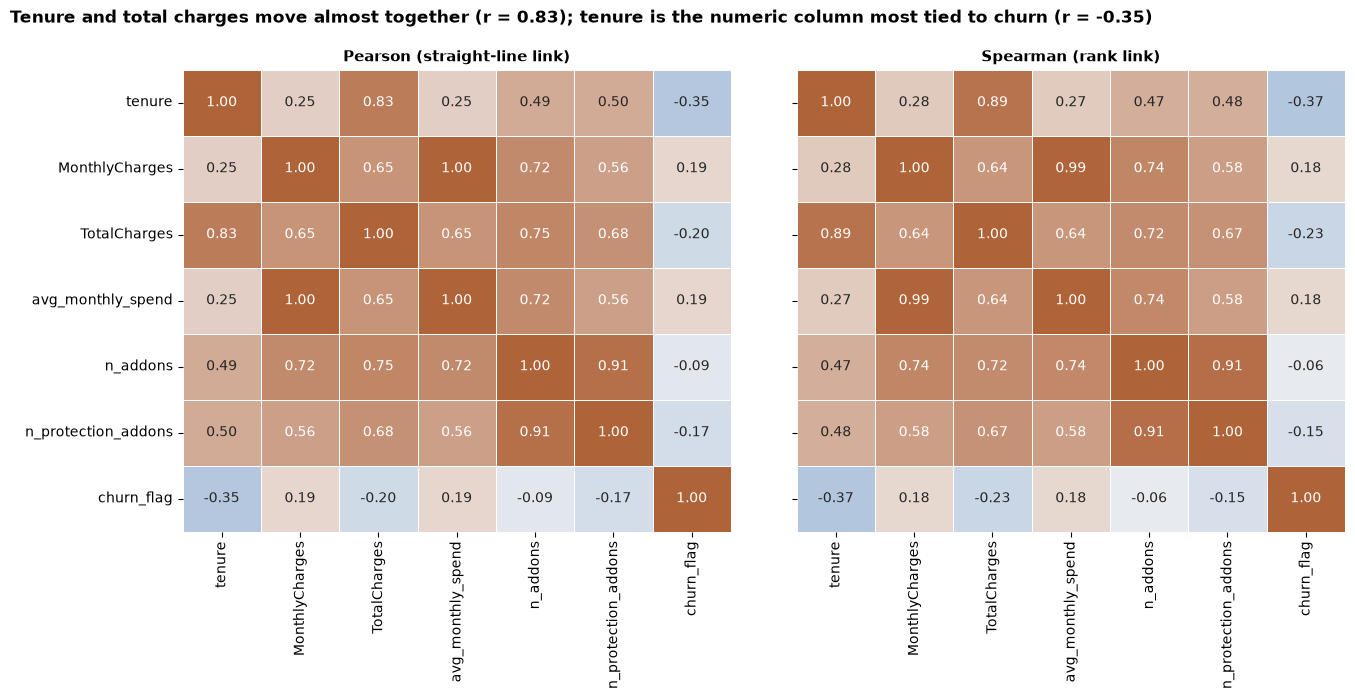

Numeric columns most linked to churn (Spearman, by absolute size):
tenure                 0.37
TotalCharges           0.23
MonthlyCharges         0.18
avg_monthly_spend      0.18
n_protection_addons    0.15
n_addons               0.06


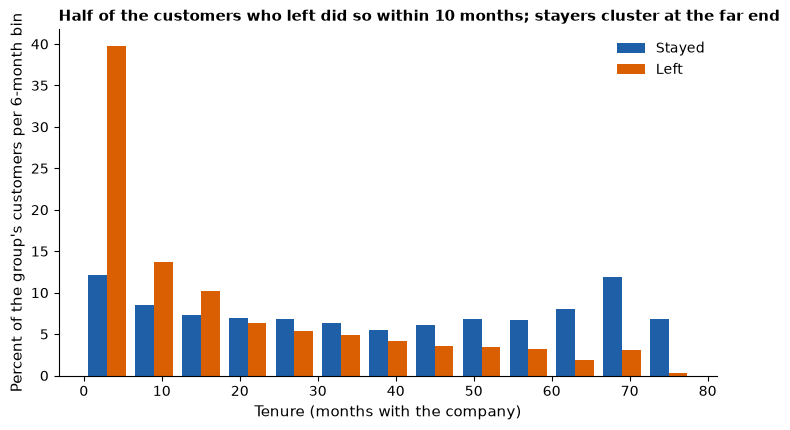

In [15]:
numc = ["tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend", "n_addons", "n_protection_addons", "churn_flag"]
pear = df[numc].corr(method="pearson"); spear = df[numc].corr(method="spearman")
display(pear.round(2)); display(spear.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"wspace": 0.12})
for ax_, m_, nm in zip(axs, [pear, spear], ["Pearson (straight-line link)", "Spearman (rank link)"]):
    sns.heatmap(m_, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 30, as_cmap=True), vmin=-1, vmax=1, ax=ax_, cbar=False, linewidths=.5)
    ax_.set_title(nm, fontsize=11)
    if ax_ is axs[1]: ax_.set_yticklabels([])
fig.suptitle(f"Tenure and total charges move almost together (r = {pear.loc['tenure','TotalCharges']:.2f}); tenure is the numeric column most tied to churn (r = {pear.loc['tenure','churn_flag']:.2f})", x=.01, ha="left", fontweight="bold", fontsize=12)
U.save(fig, CH / "16_correlations.png"); plt.show()
print("Numeric columns most linked to churn (Spearman, by absolute size):")
print(spear["churn_flag"].drop("churn_flag").abs().sort_values(ascending=False).round(2).to_string())
# distribution view
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.hist([df[df.churn_flag == 0].tenure, df[df.churn_flag == 1].tenure], bins=range(0, 80, 6), color=[BLUE, ORANGE], label=["Stayed", "Left"],
        weights=[np.full((df.churn_flag == 0).sum(), 100 / (df.churn_flag == 0).sum()), np.full((df.churn_flag == 1).sum(), 100 / (df.churn_flag == 1).sum())])
ax.set_xlabel("Tenure (months with the company)"); ax.set_ylabel("Percent of the group's customers per 6-month bin")
ax.legend(frameon=False); ax.set_title(f"Half of the customers who left did so within {df[df.churn_flag==1].tenure.median():.0f} months; stayers cluster at the far end", loc="left", fontsize=11)
U.save(fig, CH / "17_tenure_distribution.png"); plt.show()


**What the output shows.**
- Tenure and `TotalCharges` move together (0.83 Pearson, 0.89 Spearman). `MonthlyCharges` and `avg_monthly_spend` are almost the same (1.00). The two add-on counts overlap (0.91).
- Against churn, tenure has the strongest link (-0.35 Pearson, -0.37 Spearman: longer tenure, less churn). `TotalCharges` is -0.20, `MonthlyCharges` +0.19, add-on counts -0.09 and -0.17.
- Correlations are modest because churn is a yes/no outcome and the links are curved or step-shaped.
- The histogram shows leavers bunched at short tenure; stayers cluster at 60+ months. Together these mean the overlapping columns must not be used together without care.

## 7. Hypothesis tests
**What this step does.** It runs the ten pre-registered tests from section 5.1 and writes `hypotheses.md`.

| Part | Explanation |
|---|---|
| Why this method | Two groups, one yes/no outcome: the chi-square test asks whether the two churn rates differ by more than luck would produce. |
| Alternatives | Fisher's exact test (same answer at this sample size); a z-test for two proportions (equivalent to chi-square on a 2x2 table). |
| How it works: chi-square | `chi-square = sum((observed - expected)^2 / expected)` over the four cells, where "expected" is what we would see if both groups had the same rate. Bigger means a bigger surprise. |
| How it works: gap and interval | Gap = `rate A - rate B` in percentage points. The **bootstrap 95% interval** redraws each group at random with replacement 2,000 times, recomputes the gap each time, and reports the middle 95% of those gaps. It says "the true gap is plausibly in this range". |
| How it works: effect size | **phi** `= sqrt(chi-square / n)`: 0 to 1, about 0.1 small, 0.3 medium. For H6, **Mann-Whitney** ranks all customers by bill and asks how often a randomly chosen leaver pays more than a randomly chosen stayer. That chance is the **common-language effect**: 50% means no difference, 100% means leavers always pay more. |
| Alternatives for H6 (Mann-Whitney) | A Welch t-test on bills compares averages; bills are bunched and skewed, so a few high bills can move the mean, which is why we do not use it. A permutation test on the median gap gives the same answer but is slower to explain. |
| Alternatives for H9 (Mantel-Haenszel) | A logistic regression with contract and internet type is a fitted model, out of scope. Separate chi-square tests per internet type give three answers and no pooled one, and three more tests would spend more of the false-alarm budget. |
| Terms | **Odds** = leavers divided by stayers in a group (30 leavers and 70 stayers: odds 30/70 = 0.43, or "3 to 7"). **Odds ratio** = odds in one group divided by odds in the other. **Stratum** = one slice of the data held fixed, here one internet type (DSL, fiber, none); results from the three strata are combined ("pooled"). |
| How it works: pooled test (H9) | **Mantel-Haenszel** computes the odds ratio (how many times higher the odds of leaving are) in each internet type and pools them with weights. A ratio of 1 means no effect. |
| How it works: homogeneity check (Breslow-Day) | Null hypothesis: the odds ratio of month-to-month versus longer contracts is the same in every internet type. The statistic adds up, across the strata, the squared gap between the observed count and the count expected if one common odds ratio held, scaled by its variance. Large means the effect differs by type. It is a descriptive check on H9, not one of the ten pre-registered tests; we read it against the same 0.005 bar. |
| How to read it | A result is **reliable** only if p < 0.005 (Bonferroni, section 5.1) **and** the 95% interval excludes zero (excludes 1 for odds ratios). Otherwise we say "no reliable difference found". That does not prove the groups are equal; it means the data cannot tell. |

In [16]:
res = {}
def grp(mask_a, mask_b, data=df):
    return U.two_group_rate_test(data.loc[mask_a, "churn_flag"], data.loc[mask_b, "churn_flag"])
res["H1"] = dict(a="Month-to-month", b="1- or 2-year contract", data=df, ma=df.Contract == "Month-to-month", mb=df.Contract != "Month-to-month")
res["H2"] = dict(a="Fiber optic", b="DSL", data=df, ma=df.InternetService == "Fiber optic", mb=df.InternetService == "DSL")
res["H3"] = dict(a="Tenure 0-12 months", b="Tenure 13+ months", data=df, ma=df.tenure <= 12, mb=df.tenure > 12)
res["H4"] = dict(a="Electronic check", b="Other payment", data=df, ma=df.PaymentMethod == "Electronic check", mb=df.PaymentMethod != "Electronic check")
res["H5"] = dict(a="No tech support (internet customers)", b="Has tech support (internet customers)", data=inet, ma=inet.TechSupport == "No", mb=inet.TechSupport == "Yes")
res["H7"] = dict(a="Senior citizen", b="Not senior", data=df, ma=df.SeniorCitizen == 1, mb=df.SeniorCitizen == 0)
res["H8"] = dict(a="Female", b="Male", data=df, ma=df.gender == "Female", mb=df.gender == "Male")
res["H10"] = dict(a="Has phone service", b="No phone service", data=df, ma=df.PhoneService == "Yes", mb=df.PhoneService == "No")
out = {}
for k, v in res.items():
    r = grp(v["ma"], v["mb"], v["data"]); r["a"], r["b"] = v["a"], v["b"]
    sa = v["data"][v["ma"]]; r["avg_bill_of_leavers_a"] = sa.loc[sa.churn_flag == 1, "MonthlyCharges"].mean()
    r["rev_a_leavers"] = sa.loc[sa.churn_flag == 1, "MonthlyCharges"].sum()
    r["reliable"] = (r["p"] < ALPHA) and (r["ci_lo"] > 0 or r["ci_hi"] < 0)
    out[k] = r
# H6 Mann-Whitney
r6 = U.mann_whitney(df.loc[df.churn_flag == 1, "MonthlyCharges"], df.loc[df.churn_flag == 0, "MonthlyCharges"])
r6["reliable"] = (r6["p"] < ALPHA) and (r6["ci_lo"] > 0 or r6["ci_hi"] < 0)
# H9 Mantel-Haenszel
tabs, strata = [], []
for lvl in ["DSL", "Fiber optic", "No"]:
    s = df[df.InternetService == lvl]; a = s[s.Contract == "Month-to-month"].churn_flag; b = s[s.Contract != "Month-to-month"].churn_flag
    tabs.append(np.array([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]]))
    strata.append(dict(internet_type=lvl, **{k: v for k, v in U.two_group_rate_test(a, b).items() if k in ("rate_a", "rate_b", "diff_pp", "ci_lo", "ci_hi", "n_a", "n_b")}))
st = StratifiedTable(tabs); or_pooled = st.oddsratio_pooled; or_ci = st.oddsratio_pooled_confint(); p_mh = st.test_null_odds().pvalue; p_bd = st.test_equal_odds().pvalue
strata = pd.DataFrame(strata).round(1); display(strata)
r9 = dict(or_pooled=or_pooled, or_lo=or_ci[0], or_hi=or_ci[1], p=p_mh, p_homog=p_bd)
r9["reliable"] = (p_mh < ALPHA) and or_ci[0] > 1 and (strata.diff_pp > 0).all()
print(f"H9: pooled odds ratio {or_pooled:.2f} (95% interval {or_ci[0]:.2f} to {or_ci[1]:.2f}), p {fmt_p(p_mh)}; gap equal across types? p {fmt_p(p_bd)}")
print(f"H6: median bill leavers ${r6['median_x']:.2f} vs stayers ${r6['median_y']:.2f}; gap ${r6['diff']:.2f} (95% interval ${r6['ci_lo']:.2f} to ${r6['ci_hi']:.2f}); chance a leaver pays more {100*r6['cles']:.1f}%; p {fmt_p(r6['p'])}")
tests = pd.DataFrame([dict(id=k, group_a=v["a"], group_b=v["b"], n_a=v["n_a"], n_b=v["n_b"], rate_a_pct=round(v["rate_a"], 1), rate_b_pct=round(v["rate_b"], 1),
        gap_pp=round(v["diff_pp"], 1), ci_95=f"{v['ci_lo']:.1f} to {v['ci_hi']:.1f}", p=fmt_p(v["p"]), phi=round(v["phi"], 3), reliable=v["reliable"]) for k, v in out.items()])
display(tests)
print("Verdicts:", {k: ("reliable" if v["reliable"] else "no reliable difference") for k, v in out.items()}, "| H6:", r6["reliable"], "| H9:", r9["reliable"])


,internet_type,rate_a,rate_b,diff_pp,ci_lo,ci_hi,n_a,n_b
0,DSL,32.2,5.4,26.8,23.8,29.7,1223,1198
1,Fiber optic,54.6,13.9,40.7,37.7,43.7,2128,968
2,No,18.9,1.4,17.5,14.1,21.0,524,1002


H9: pooled odds ratio 8.22 (95% interval 7.03 to 9.61), p below 0.0001; gap equal across types? p 0.0323
H6: median bill leavers $79.65 vs stayers $64.43; gap $15.22 (95% interval $13.90 to $17.90); chance a leaver pays more 62.1%; p below 0.0001


,id,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,gap_pp,ci_95,p,phi,reliable
0,H1,Month-to-month,1- or 2-year contract,3875,3168,42.7,6.8,36.0,34.2 to 37.8,below 0.0001,0.405,True
1,H2,Fiber optic,DSL,3096,2421,41.9,19.0,22.9,20.5 to 25.2,below 0.0001,0.244,True
2,H3,Tenure 0-12 months,Tenure 13+ months,2186,4857,47.4,17.1,30.3,27.9 to 32.6,below 0.0001,0.318,True
3,H4,Electronic check,Other payment,2365,4678,45.3,17.1,28.2,25.9 to 30.5,below 0.0001,0.302,True
4,H5,No tech support (internet customers),Has tech support (internet customers),3473,2044,41.6,15.2,26.5,24.3 to 28.8,below 0.0001,0.274,True
5,H7,Senior citizen,Not senior,1142,5901,41.7,23.6,18.1,14.9 to 21.2,below 0.0001,0.151,True
6,H8,Female,Male,3488,3555,26.9,26.2,0.8,-1.3 to 2.8,0.4698,0.009,False
7,H10,Has phone service,No phone service,6361,682,26.7,24.9,1.8,-1.8 to 5.1,0.3162,0.012,False


Verdicts: {'H1': 'reliable', 'H2': 'reliable', 'H3': 'reliable', 'H4': 'reliable', 'H5': 'reliable', 'H7': 'reliable', 'H8': 'no reliable difference', 'H10': 'no reliable difference'} | H6: True | H9: True


**What the output shows.**
- H1 to H5 and H7: all reliable, with 95% intervals far from zero. Gaps: month-to-month +36.0 points (95% interval +34.2 to +37.8), fiber vs DSL +22.9, first year vs later +30.3, electronic check +28.2, no tech support +26.5, seniors +18.1.
- H6: leavers' median bill is $79.65 against $64.43; a random leaver pays more than a random stayer 62% of the time (50% = no difference). Reliable.
- H9: the odds of leaving on month-to-month are about 8.2 times higher after holding internet type fixed (95% interval 7.0 to 9.6). The gap in points differs by type (DSL +26.8, fiber +40.7, none +17.5), but that difference is not reliable at our bar (p = 0.03 against 0.005).
- H8 gender (gap +0.8 points, interval -1.3 to +2.8) and H10 phone service (+1.8, interval -1.8 to +5.1): no reliable difference, as predicted.

### 7.1 Write the hypotheses file
**What this step does.** It turns the test results into plain-language verdicts with business-sized effects and "what would change the conclusion", then writes `hypotheses.md`.

**Business-sized effect.** For each rate test: `extra leavers per 1,000 customers = gap in points x 10`, and `revenue at stake = (gap in points / 100) x customers in group A x average monthly bill of group A's leavers`. This is what A's monthly revenue loss would shrink by if A left at B's rate. It is an upper bound for what any programme could recover, not a forecast.

In [17]:
def verdict(v):
    if v["reliable"]: return "Reliable: the data supports this statement."
    return "Not reliable: no difference that luck could not explain was found (this is not proof that the groups are equal)."
CHANGE = {
 "H1": "Contract terms that were assigned (not chosen) by customers, or a second quarter of data showing the gap shrinking.",
 "H2": "Evidence that fiber customers differ in price or tenure in a way not captured here; the price gap is checked in section 6 but not removed.",
 "H3": "Knowing whether tenure for leavers is measured at exit. If so, tenure partly reflects the outcome. Unclear from this data.",
 "H4": "Evidence that payment method is simply a stand-in for how customers were signed up. Unclear from this data.",
 "H5": "A check that tech support was bought before, not after, the customer decided to stay. Unclear from this data.",
 "H6": "Comparing like-for-like plans: leavers may pay more because they are mostly on fiber. Section 6.5 and H9 show overlap exists.",
 "H7": "Controlling for contract and tenure. We did not adjust, so some of the senior gap may come from other columns.",
 "H8": "A larger sample. With 7,043 customers we could detect a gap of about 3 points; a smaller gap would be invisible.",
 "H9": "A fourth internet type, or a stratum where month-to-month customers were chosen differently.",
 "H10": "A larger sample or a split of phone-only customers (only 682 have no phone service).",
}
pred = PREREG.set_index("id").predicted_direction.to_dict()
H = []
def money_unit(v):
    gap = v["diff_pp"]; extra_per_1000 = gap * 10
    rev = (gap / 100) * v["n_a"] * v["avg_bill_of_leavers_a"]
    return extra_per_1000, rev
blocks = []
for k in ["H1","H2","H3","H4","H5","H6","H7","H8","H9","H10"]:
    if k == "H6":
        v = r6; ev = f"Median monthly bill is ${v['median_x']:.2f} for the {int(v['n_x']):,} customers who left and ${v['median_y']:.2f} for the {int(v['n_y']):,} who stayed."
        eff = f"Gap in medians: ${v['diff']:.2f} per month (95% interval ${v['ci_lo']:.2f} to ${v['ci_hi']:.2f}). A random leaver pays more than a random stayer {100*v['cles']:.0f}% of the time (50% would mean no difference)."
        ver = verdict(v); p_ = v["p"]; agree = "matches" if (v["diff"] > 0) else "opposes"
    elif k == "H9":
        ev = "Month-to-month versus longer contracts, churn rate by internet type: " + "; ".join(f"{r.internet_type} {r.rate_a:.0f}% vs {r.rate_b:.0f}%" for r in strata.itertuples()) + "."
        eff = f"Pooled odds ratio {r9['or_pooled']:.1f} (95% interval {r9['or_lo']:.1f} to {r9['or_hi']:.1f}): the odds of leaving are about {r9['or_pooled']:.0f} times higher on month-to-month, after holding internet type fixed. Gap in points per type: " + ", ".join(f"{r.internet_type} {r.diff_pp:+.0f}" for r in strata.itertuples()) + "."
        ver = verdict(r9); p_ = r9["p"]; agree = "matches" if r9["reliable"] else "opposes"
    else:
        v = out[k]; ev = f"{v['a']}: {v['rate_a']:.1f}% left ({v['n_a']:,} customers). {v['b']}: {v['rate_b']:.1f}% left ({v['n_b']:,} customers)."
        ex, rev = money_unit(v)
        money_txt = f" If group A left at B's rate, about ${rev:,.0f} of monthly revenue would stay (an upper bound, not a forecast)." if v["reliable"] else " No reliable gap, so no revenue effect is claimed."
        eff = f"Gap {v['diff_pp']:+.1f} points (95% interval {v['ci_lo']:+.1f} to {v['ci_hi']:+.1f}); {ex:+.0f} extra leavers per 1,000 customers; phi (effect size) {v['phi']:.2f}." + money_txt
        ver = verdict(v); p_ = v["p"]
        exp_null = pred[k] == "no difference expected"
        agree = ("matches" if not v["reliable"] else "opposes") if exp_null else ("matches" if v["reliable"] and v["diff_pp"] > 0 else "opposes")
    blocks.append(f"### {k}. {PREREG.set_index('id').statement[k]}\n\n- **Predicted:** {pred[k]}. Result {agree} the prediction.\n- **Evidence seen:** {ev}\n- **Size of effect:** {eff}\n- **Reliability:** {ver} p-value {fmt_p(p_)}, against the pre-set bar of {ALPHA}.\n- **What would change the conclusion:** {CHANGE[k]}\n")
    H.append((k, agree, bool(out[k]["reliable"]) if k not in ("H6", "H9") else bool(r6["reliable"] if k == "H6" else r9["reliable"])))
n_rel = sum(1 for _, _, r in H if r)
unsupported = [k for k, a, r in H if a == "opposes" or (not r)]
hyp_md = (f"# Hypotheses\n\nTen statements, written down before the group comparisons (see the pre-registration table in the notebook, section 5.1). "
          f"Bar for reliable: p below {ALPHA} (5% divided by 10 tests) and a 95% interval that excludes zero (or 1 for odds ratios). "
          f"These tests use the same data that suggested the ideas, so they are not independent confirmation.\n\n## Pre-registered plan (fixed before the results)\n\n" + md_table(PREREG, index=False) + "\n\nOdds = leavers divided by stayers in a group. Odds ratio = odds in one group divided by odds in another. Stratum = one slice held fixed (one internet type). phi = strength of a 2-group link, 0 to 1.\n\n## Scorecard\n\n"
          + md_table(pd.DataFrame([dict(id=k, statement=PREREG.set_index("id").statement[k], prediction=pred[k], result_vs_prediction=a, reliable="yes" if r else "no") for k, a, r in H]), index=False)
          + f"\n\n**{n_rel} of 10 statements are reliable. Not supported by the data: {', '.join(unsupported)}.**\n\n## Detail\n\n" + "\n".join(blocks)
          + "\n## Group-comparison table\n\n" + md_table(tests, index=False) + "\n\nNot checked: any adjustment for several columns at once, any time effect (the data is one snapshot), any cause.\n")
write("hypotheses.md", hyp_md)
print(hyp_md[:3500])


wrote hypotheses.md (13,016 characters)
# Hypotheses

Ten statements, written down before the group comparisons (see the pre-registration table in the notebook, section 5.1). Bar for reliable: p below 0.005 (5% divided by 10 tests) and a 95% interval that excludes zero (or 1 for odds ratios). These tests use the same data that suggested the ideas, so they are not independent confirmation.

## Pre-registered plan (fixed before the results)

| id | statement | predicted_direction | test | effect_size_and_why |
|---|---|---|---|---|
| H1 | Month-to-month leave more often than 1-2 year contracts | month-to-month higher | chi-square on two groups + bootstrap 95% interval on the gap | phi, plus the gap in points. Phi (0 to 1; about 0.1 small, 0.3 medium) can be compared across tests; points are what a manager can price. |
| H2 | Fiber-optic leave more often than DSL | fiber higher | chi-square on two groups + bootstrap 95% interval on the gap | phi, plus the gap in points. Same reason as H1.

**What the output shows.** `hypotheses.md` lists a scorecard and detail for each statement. 8 of 10 are reliable. H8 and H10 are not supported by the data: gender and phone service show no reliable churn gap. Each entry has the evidence, the effect in customers and dollars, the verdict and what would change it. Revenue effects are upper bounds, not forecasts.

## 8. Findings, hand-off and final checks
### 8.1 Write `findings.md`
**What this step does.** It assembles the findings file from the variables computed above, so every number in the file is the number in the notebook. Each chart gets three lines: what it shows, what it means for the business question, how sure we can be.

**How "how sure" is judged.** We use the verdicts from section 7 (reliable only if p < 0.005 and the 95% interval excludes zero) and the customer count behind each bar. Small groups (under 100 customers) are called out. All rates are from one snapshot of one quarter, so none of them says why customers leave.

In [18]:
ct = tables["Contract"]; it = tables["InternetService"]; pm = tables["PaymentMethod"]
t06 = tn.loc["0-6 months"]; m12 = cand.set_index("group")
g_a = m12.loc["Month-to-month, first 12 months"]; g_b = m12.loc["Month-to-month on fiber, first 12 months"]; g_c = m12.loc["Month-to-month (any)"]
tech_y = ad[(ad.addon == "TechSupport") & (ad.has_it == "Yes")].churn_rate_pct.iloc[0]; tech_n = ad[(ad.addon == "TechSupport") & (ad.has_it == "No")].churn_rate_pct.iloc[0]
sec_y = ad[(ad.addon == "OnlineSecurity") & (ad.has_it == "Yes")].churn_rate_pct.iloc[0]; sec_n = ad[(ad.addon == "OnlineSecurity") & (ad.has_it == "No")].churn_rate_pct.iloc[0]
ec = pm.loc["Electronic check"]
fiber_in_mtm = p1.loc["Month-to-month", "Fiber optic"]; dsl_in_mtm = p1.loc["Month-to-month", "DSL"]
ten_ratio = tn.loc["0-6 months", "churn_rate_pct"] / tn.loc["49-72 months", "churn_rate_pct"]
ten0 = df.tenure.eq(0).sum()
ten_p4 = p2.loc["0-6 months"]
etop = rank.iloc[:3].column.tolist()
ten_med = df[df.churn_flag == 1].tenure.median()
retain10 = 0.10 * g_b.monthly_rev_lost_usd

SUMMARY = f"""## Summary: the five findings that matter most

Base: {N:,} customers, {n_churn:,} left ({100*base_rate:.1f}%). They paid ${mrr_lost:,.0f} a month, {100*mrr_lost/mrr_all:.1f}% of ${mrr_all:,.0f} monthly revenue. Rates below are shares of the customers in each group. None says why customers leave.

1. **Contract type is the strongest single link to churn.** Month-to-month customers leave at {ct.loc['Month-to-month','churn_rate_pct']:.1f}% ({ct.loc['Month-to-month','customers']:,.0f} customers); two-year customers at {ct.loc['Two year','churn_rate_pct']:.1f}%. Month-to-month holds {ct.loc['Month-to-month','share_of_churners_pct']:.1f}% of leavers and {100*ct.loc['Month-to-month','monthly_rev_lost_usd']/mrr_lost:.1f}% of lost revenue. Reliable (H1). Chart: `charts/03_churn_by_contract.png`.
2. **New customers leave at the highest rate.** Months 0-6: {t06.churn_rate_pct:.1f}% ({t06.customers:,.0f} customers, {t06.share_of_base_pct:.0f}% of base), holding {t06.share_of_churners_pct:.0f}% of leavers. After 4 years: {tn.loc['49-72 months','churn_rate_pct']:.1f}%. Reliable (H3). Chart: `charts/04_churn_by_tenure.png`.
3. **Fiber-optic customers leave at about twice the DSL rate, and the gap is not just a contract effect.** Fiber {it.loc['Fiber optic','churn_rate_pct']:.1f}% versus DSL {it.loc['DSL','churn_rate_pct']:.1f}%; fiber holds {it.loc['Fiber optic','share_of_churners_pct']:.0f}% of leavers. On month-to-month alone: fiber {fiber_in_mtm:.0f}% versus DSL {dsl_in_mtm:.0f}%. Reliable (H2). Chart: `charts/10_heat_contract_by_internet.png`.
4. **Electronic-check payers leave at {ec.churn_rate_pct:.1f}%, against {pm.loc['Credit card (automatic)','churn_rate_pct']:.1f}% to {pm.loc['Mailed check','churn_rate_pct']:.1f}% for the other three methods.** They are {ec.share_of_base_pct:.0f}% of customers and {ec.share_of_churners_pct:.0f}% of leavers. The gap holds on month-to-month contracts ({e_m:.0f}% versus about {a_m:.0f}% for automatic payers). Reliable (H4). Chart: `charts/12_heat_payment_by_contract.png`.
5. **A small, well-defined group holds a large share of the loss: month-to-month fiber customers in their first 12 months.** {int(g_b.customers):,} customers ({g_b.share_of_base_pct:.0f}% of base) leave at {g_b.churn_rate_pct:.0f}%, and hold {g_b.share_of_all_churners_pct:.0f}% of leavers and ${g_b.monthly_rev_lost_usd:,.0f} of monthly revenue lost ({g_b.share_of_lost_rev_pct:.0f}% of the total). Each 10% of that group's leavers kept is worth ${retain10:,.0f} a month (${12*retain10:,.0f} a year). Widening to all month-to-month customers in year one covers {g_a.share_of_all_churners_pct:.0f}% of leavers. Chart: `charts/15_candidate_groups_revenue.png`.

Also notable: internet customers without tech support leave at {tech_n:.0f}% versus {tech_y:.0f}% with it (H5, reliable); no link was found for gender or for having phone service (H8, H10).
"""

notes = [
 ("01_target_customers_vs_revenue.png", "Leavers are a bigger share of revenue than of customers.", f"{100*base_rate:.1f}% of customers left, taking {100*mrr_lost/mrr_all:.1f}% of monthly revenue. Leavers pay ${avg_ch:.2f} a month on average against ${avg_st:.2f} for stayers.", "Sure of the arithmetic. The bill difference is reliable (H6)."),
 ("02_churn_rate_all_categories.png", "Churn rate of every category of every column, sorted.", f"The spread is wide: from {long.rate.min():.0f}% to {long.rate.max():.0f}%. Contract, internet type and payment method hold the extremes. Gender and phone service sit on the average line.", "Every category has 300+ customers, so each rate is stable to about +/- 5 points."),
 ("03_churn_by_contract.png", "Churn rate by contract type.", f"Month-to-month {ct.loc['Month-to-month','churn_rate_pct']:.1f}%, one-year {ct.loc['One year','churn_rate_pct']:.1f}%, two-year {ct.loc['Two year','churn_rate_pct']:.1f}%. Any retention budget starts with month-to-month customers ({ct.loc['Month-to-month','share_of_base_pct']:.0f}% of base).", f"High. Gap {out['H1']['diff_pp']:.0f} points, 95% interval {out['H1']['ci_lo']:.0f} to {out['H1']['ci_hi']:.0f} (H1). Contracts are chosen by customers, so the gap is a link, not proof that a contract changes behaviour."),
 ("04_churn_by_tenure.png", "Churn rate by months with the company.", f"Falls from {tn.iloc[0].churn_rate_pct:.0f}% to {tn.iloc[-1].churn_rate_pct:.0f}% as tenure grows. The first 6 months hold {t06.share_of_churners_pct:.0f}% of leavers. Early-life offers have the most customers to act on.", f"High on size (H3: first 12 months {out['H3']['rate_a']:.0f}% versus {out['H3']['rate_b']:.0f}%). Unclear from this data whether tenure of leavers is measured at exit, which would make low-tenure leavers partly built in."),
 ("05_churn_by_internet.png", "Churn rate by internet type.", f"Fiber {it.loc['Fiber optic','churn_rate_pct']:.1f}%, DSL {it.loc['DSL','churn_rate_pct']:.1f}%, no internet {it.loc['No','churn_rate_pct']:.1f}%. Fiber is {it.loc['Fiber optic','share_of_base_pct']:.0f}% of customers and {it.loc['Fiber optic','share_of_churners_pct']:.0f}% of leavers.", f"High (H2: gap {out['H2']['diff_pp']:.0f} points). The data has no service-quality or price-history field, so why fiber leaves more is unclear from this data."),
 ("06_churn_by_payment.png", "Churn rate by payment method.", f"Electronic check {ec.churn_rate_pct:.1f}%; the other three {pm.loc['Credit card (automatic)','churn_rate_pct']:.0f}-{pm.loc['Mailed check','churn_rate_pct']:.0f}%. Automatic payers are the most loyal group.", f"High (H4: gap {out['H4']['diff_pp']:.0f} points). Payment method may stand in for contract or sign-up route; the two-way chart 12 checks contract only."),
 ("07_churn_by_monthly_charge.png", "Churn rate by monthly bill band.", f"Lowest under $30 ({mc.loc['under $30','churn_rate_pct']:.0f}%), highest at $70-90 ({mc.loc['$70-90','churn_rate_pct']:.0f}%). The pattern is not a straight climb: $30-50 ({mc.loc['$30-50','churn_rate_pct']:.0f}%) beats $50-70 ({mc.loc['$50-70','churn_rate_pct']:.0f}%). The $70+ bands hold {100*mc.loc[['$70-90','$90+'],'monthly_rev_lost_usd'].sum()/mrr_lost:.0f}% of lost revenue.", f"Medium. Leavers pay ${r6['diff']:.0f} more at the median (H6, reliable), but price overlaps with fiber and add-ons, so price on its own is unclear from this data."),
 ("08_churn_by_addon.png", "Churn with and without each add-on, internet customers only.", f"Security ({sec_y:.0f}% versus {sec_n:.0f}%), tech support ({tech_y:.0f}% versus {tech_n:.0f}%), backup and device protection show large gaps. Streaming add-ons show a much smaller gap (about 4 points). Customers with four protection add-ons leave at {cnt.loc[4,'churn_rate_pct']:.0f}%; with none, {cnt.loc[0,'churn_rate_pct']:.0f}%.", f"High for tech support (H5: gap {out['H5']['diff_pp']:.0f} points). Customers who choose add-ons may differ in other ways; unclear from this data whether adding one changes anything."),
 ("10_heat_contract_by_internet.png", "Churn by contract and internet type.", f"Month-to-month is highest in all three internet types (fiber {fiber_in_mtm:.0f}%, DSL {dsl_in_mtm:.0f}%, none {p1.loc['Month-to-month','No']:.0f}%). Fiber and contract each add risk.", f"High (H9: pooled odds ratio {r9['or_pooled']:.1f}, 95% interval {r9['or_lo']:.1f} to {r9['or_hi']:.1f}). All cells have 100+ customers."),
 ("11_heat_tenure_by_contract.png", "Churn by tenure band and contract.", f"Churn falls with tenure inside month-to-month ({m_first:.0f}% to {m_late:.0f}%). Two-year contracts stay low at every age.", f"Medium. {int((n2 < 100).sum().sum())} of 15 cells have under 100 customers (marked *), mostly long contracts in the first months. Read only the large cells."),
 ("12_heat_payment_by_contract.png", "Churn by payment method and contract.", f"Within month-to-month, electronic check {e_m:.0f}% against about {a_m:.0f}% for automatic payers. The payment gap is not just a contract effect.", "High on the month-to-month row (large cells). Unclear for other contracts where cells are smaller."),
 ("13_heat_techsupport_by_internet.png", "Churn by tech support and internet type, internet customers only.", f"Tech support goes with lower churn on DSL ({p4.loc['Yes','DSL']:.0f}% versus {p4.loc['No','DSL']:.0f}%) and fiber ({p4.loc['Yes','Fiber optic']:.0f}% versus {p4.loc['No','Fiber optic']:.0f}%).", "High. All four cells have 100+ customers."),
 ("14_concentration_curve.png", "Cumulative share of churn against customers, riskiest of 17 observed segments first.", f"The riskiest 20% of customers hold about {conc20[0]:.0f}% of leavers and {conc20[1]:.0f}% of lost revenue; the riskiest 30%, {conc30[0]:.0f}% and {conc30[1]:.0f}%. Churn is concentrated; broad programmes waste most of their budget.", "Medium. The ranking is built and read on the same customers, so the picture is slightly flattering; five tiny segments (under 100 customers) hold under 2% of customers."),
 ("15_candidate_groups_revenue.png", "Seven simple, targetable groups: share of customers against share of lost revenue.", f"Month-to-month on fiber in year one: {g_b.share_of_base_pct:.0f}% of customers, {g_b.share_of_lost_rev_pct:.0f}% of lost revenue. Every group on the chart takes a bigger share of loss than of customers.", "High on the counts (each group has 900+ customers). Whether an offer would keep these customers is not testable from this data."),
 ("16_correlations.png", "Correlation among numeric columns and with churn.", f"Tenure and TotalCharges move together (r = {pear.loc['tenure','TotalCharges']:.2f}); MonthlyCharges and avg_monthly_spend are almost the same (r = {pear.loc['MonthlyCharges','avg_monthly_spend']:.2f}); add-on counts overlap (r = {pear.loc['n_addons','n_protection_addons']:.2f}). Tenure has the strongest link to churn (r = {pear.loc['tenure','churn_flag']:.2f}); the model builder should not use these overlapping columns together without care.", "High for the numbers; a correlation measures a straight-line link only."),
 ("17_tenure_distribution.png", "Tenure of leavers against stayers.", f"Leavers bunch at the start (median {ten_med:.0f} months); stayers bunch at the far end.", "High on the shape. Whether leavers' tenure is recorded at exit is unclear from this data."),
]
chart_md = "\n".join(f"### `charts/{f}`\n- **Shows:** {a}\n- **Means for the business question:** {b}\n- **How sure:** {c}\n" for f, a, b, c in notes)

rank_md = md_table(rank[["column", "cramers_v", "highest_rate_category", "highest_rate_pct", "lowest_rate_category", "lowest_rate_pct"]], index=False)
seg_md = md_table(seg[["customers", "churn_rate_pct", "share_of_base_pct", "share_of_churners_pct", "monthly_rev_lost_usd", "share_of_rev_lost_pct"]].round(1))
cand_md = md_table(cand.drop(columns="churners_per_100_customers_targeted"), index=False)
findings_md = f"""# Findings: what the data says about churn

{SUMMARY}
## Business framing

{md_table(tgt, index=False)}

All money is monthly recurring revenue from `MonthlyCharges`. Margin, acquisition cost and lifetime value are not in the data, so they are not estimated.

## Ranked drivers (how strongly each column is linked to churn)

Cramér's V runs from 0 (no link) to 1 (perfect link). Under 0.1 is weak, 0.1 to 0.3 moderate, over 0.3 strong. Top three: {', '.join(etop)}. Gender and phone service are at or near zero.

{rank_md}

Note: for the six add-on columns the table above includes customers with no internet in the "No" group, who rarely leave ({it.loc['No','churn_rate_pct']:.1f}%). Chart 08 compares internet customers only, which is the fairer view.

## Where churn concentrates

Revenue lost per segment, riskiest first (segments under 100 customers are noisy):

{seg_md}

## Candidate groups for a first intervention

Counts are descriptive. "Monthly revenue lost" is the sum of monthly bills of the group's leavers.

{cand_md}

Reading it: the narrower the group, the higher its churn rate, but the fewer leavers it reaches. The group in finding 5 reaches {g_b.share_of_all_churners_pct:.0f}% of leavers by contacting {g_b.share_of_base_pct:.0f}% of customers. Month-to-month customers in year one reach {g_a.share_of_all_churners_pct:.0f}% of leavers by contacting {g_a.share_of_base_pct:.0f}%. Which is smaller-but-enough depends on offer cost and save rate, which this data does not contain.

## Charts

{chart_md}
## What we did not find, and what we could not check

- No reliable link between gender and churn ({out['H8']['rate_a']:.1f}% versus {out['H8']['rate_b']:.1f}%) or between phone service and churn ({out['H10']['rate_a']:.1f}% versus {out['H10']['rate_b']:.1f}%).
- Causes: none. The data is one snapshot. "Customers with X leave more often" is as far as it goes.
- Time: no date column, so no trend, seasonality or "who left first". Unclear from this data.
- Tenure and TotalCharges for leavers may be measured at exit: could make them look more predictive than they are. Unclear from this data.
- Several columns at once: tables look at one or two columns. Nothing here separates their combined effects; that is for the model.
- Prices, discounts and service faults are not in the data.
- The data is IBM's fictional sample, so conclusions describe the data, not a real company.
- KKBox transactions were profiled only (no outcome label); nothing from them is in these findings.
"""
write("findings.md", findings_md)
print(SUMMARY)


wrote findings.md (14,761 characters)
## Summary: the five findings that matter most

Base: 7,043 customers, 1,869 left (26.5%). They paid $139,131 a month, 30.5% of $456,117 monthly revenue. Rates below are shares of the customers in each group. None says why customers leave.

1. **Contract type is the strongest single link to churn.** Month-to-month customers leave at 42.7% (3,875 customers); two-year customers at 2.8%. Month-to-month holds 88.5% of leavers and 86.9% of lost revenue. Reliable (H1). Chart: `charts/03_churn_by_contract.png`.
2. **New customers leave at the highest rate.** Months 0-6: 52.9% (1,481 customers, 21% of base), holding 42% of leavers. After 4 years: 9.5%. Reliable (H3). Chart: `charts/04_churn_by_tenure.png`.
3. **Fiber-optic customers leave at about twice the DSL rate, and the gap is not just a contract effect.** Fiber 41.9% versus DSL 19.0%; fiber holds 69% of leavers. On month-to-month alone: fiber 55% versus DSL 32%. Reliable (H2). Chart: `charts/10_heat_

**What the output shows.** The summary block holds the five findings, each with its number and chart file. `findings.md` also has the driver ranking, the segment table, the candidate-group table, three lines for every chart and a list of what we could not check.

### 8.2 Write the hand-off for the model builder
**What this step does.** It writes `handoff_to_modeling.md`: file, target, columns to exclude, encoding, validation design, pitfalls, and the business metric.

**Margin of error used below.** `moe = 1.96 x sqrt(0.25 / leavers in the holdout) x 100` points. 1.96 is the multiplier for a 95% interval. 0.25 is p x (1 - p) at p = 0.5, the worst case, so the margin is never understated. It applies to a rate measured on the leavers in the holdout (for example, recall).

**Why these choices.** The validation design follows the data shape (one row per customer, no dates, 26.5% positives). The metric follows the business question (revenue kept, not only accuracy).

In [19]:
cat_enc = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
           "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
num_in = ["tenure", "MonthlyCharges", "SeniorCitizen", "has_internet", "n_addons", "n_protection_addons", "autopay"]
risky = ["TotalCharges", "avg_monthly_spend", "price_vs_history_pct"]
holdout_n = round(0.2 * N); holdout_pos = round(0.2 * n_churn); moe = 1.96 * np.sqrt(.25 / holdout_pos) * 100
base_cap20 = conc20[1]
HANDOFF = f"""# Hand-off to the model builder

## Files
- Cleaned table: `reports/exploration/clean.parquet` ({N:,} rows, one per customer, {N_CLEAN_COLS} columns).
- Column meanings and notes: `reports/exploration/data_dictionary.md` and `.csv`.
- The KKBox file is not in the table (no churn label).

## Target
- `churn_flag` (1 = customer left, 0 = stayed). Rate {100*base_rate:.1f}% ({n_churn:,} of {N:,}). It is the numeric copy of `Churn` (Yes/No).

## Columns to exclude, and why
| Column | Why |
|---|---|
| `customerID` | Identifier. Keep only to join scores back to customers. |
| `Churn` | Text copy of the target. |
| `tenure_band`, `monthly_charge_band` | Reporting bands built from `tenure` and `MonthlyCharges`. Redundant. |
| `TotalCharges`, `avg_monthly_spend`, `price_vs_history_pct` | Built from lifetime billing. For leavers the total stops at exit, so these can carry the outcome. Drop from the first model; add back only after a leakage check. `TotalCharges` has {int(df.TotalCharges.isna().sum())} missing values (tenure-0 accounts). |
| `has_internet` or `InternetService` | Same information. Use one. |
| `n_addons`, `n_protection_addons` | Counts of columns already present. Use the counts or the originals, not both. |

## Suggested inputs
- Categorical, need encoding (one-hot; `Contract` can also be coded as ordered 0/1/2): {', '.join(cat_enc)}.
- Numeric: {', '.join(num_in)}. `SeniorCitizen`, `has_internet`, `autopay` are already 0/1.
- Add-on columns now hold only Yes/No. Customers with no internet are "No" on all six; keep `InternetService` so the model can tell "no internet" from "declined the add-on".

## Validation design
1. Hold out a random {holdout_n:,}-customer test set (20%), stratified on `churn_flag`, seed {SEED}. It will hold about {holdout_pos} leavers. Touch it once, at the end.
2. On the other 80%, use repeated stratified 5-fold cross-validation (5 repeats) to choose and tune.
3. Why: one row per customer, so rows are independent and no grouping is needed. There is no date, so a time-based split is impossible. Stratifying keeps {100*base_rate:.1f}% leavers in every fold. With about {holdout_pos} leavers in the test set, a rate estimated on it is uncertain by about +/- {moe:.0f} points, so report intervals, not single numbers.
4. Any group ranking or threshold must be set on training folds only. The segment ranking in this exploration used all customers and is optimistic.

## Known pitfalls
- **Collinearity:** tenure and TotalCharges (r = {pear.loc['tenure','TotalCharges']:.2f}); MonthlyCharges and avg_monthly_spend (r = {pear.loc['MonthlyCharges','avg_monthly_spend']:.2f}); n_addons and n_protection_addons (r = {pear.loc['n_addons','n_protection_addons']:.2f}); add-ons and InternetService.
- **Leakage (unclear from this data):** tenure and billing totals for leavers may be measured at exit. If so, a model learns "short tenure" partly because the customer already left. Ask the data owner.
- **Small cells:** segments with under 100 customers: {', '.join(seg[seg.customers < 100].index)}. Do not report rates for them. Two-way cells of tenure band by contract also have {int((n2 < 100).sum().sum())} small cells.
- **No customers with tenure 0 left** ({ten0} accounts, all with blank TotalCharges). Do not over-read them.
- **Fairness:** gender shows no churn link; `SeniorCitizen` does (V = {rank.set_index('column').loc['SeniorCitizen','cramers_v']:.2f}). Check the policy before using age-related fields to decide who gets offers.
- **Overlap of drivers:** contract, tenure, internet type, payment method and price overlap. Single-column effects in this exploration will shrink when combined in a model.

## Business metric the model should be judged on
- **Primary:** share of lost monthly revenue captured in the top 20% of customers by risk score, on the held-out set. Reference to beat: the simple contract x internet x tenure ranking captures about {base_cap20:.0f}% at 20% of customers (in-sample, so a fair model must be compared on held-out data too). Total lost monthly revenue to capture: ${mrr_lost:,.0f}.
- **Secondary:** precision (share of flagged customers who really leave) and recall (share of leavers flagged) at the same cut-off; area under the precision-recall curve; calibration (do customers scored 40% leave about 40% of the time?).
- **Decision value:** `monthly revenue kept = (leavers contacted) x (save rate) x (average bill ${avg_ch:.2f})` minus `(customers contacted) x (cost per offer)`. Save rate and offer cost are not in the data; they must come from the client or a test.
"""
write("handoff_to_modeling.md", HANDOFF)
print(HANDOFF[:2500])


wrote handoff_to_modeling.md (4,573 characters)
# Hand-off to the model builder

## Files
- Cleaned table: `reports/exploration/clean.parquet` (7,043 rows, one per customer, 30 columns).
- Column meanings and notes: `reports/exploration/data_dictionary.md` and `.csv`.
- The KKBox file is not in the table (no churn label).

## Target
- `churn_flag` (1 = customer left, 0 = stayed). Rate 26.5% (1,869 of 7,043). It is the numeric copy of `Churn` (Yes/No).

## Columns to exclude, and why
| Column | Why |
|---|---|
| `customerID` | Identifier. Keep only to join scores back to customers. |
| `Churn` | Text copy of the target. |
| `tenure_band`, `monthly_charge_band` | Reporting bands built from `tenure` and `MonthlyCharges`. Redundant. |
| `TotalCharges`, `avg_monthly_spend`, `price_vs_history_pct` | Built from lifetime billing. For leavers the total stops at exit, so these can carry the outcome. Drop from the first model; add back only after a leakage check. `TotalCharges` has 11 missing val

**What the output shows.** `handoff_to_modeling.md` names `churn_flag` as the target, lists columns to exclude (id, text target, bands, billing-total columns), gives encoding advice, and sets a stratified 20% holdout of 1,409 customers (about 374 leavers) plus repeated 5-fold cross-validation. The metric is the share of lost monthly revenue captured in the top 20% of scored customers, with a reference of about 52% for the simple segment ranking (in-sample).

### 8.3 Final checks
**What this step does.** It confirms every promised file exists, every chart is saved at 200 dpi, and the cleaned file matches the audit.

In [20]:
import glob
from PIL import Image
files = ["data_dictionary.md", "data_dictionary.csv", "quality_audit.md", "cleaning_log.md", "clean.parquet", "findings.md", "hypotheses.md", "handoff_to_modeling.md"]
for f in files:
    p = REP / f; print(f"{f:28s} exists={p.exists()} size={p.stat().st_size:,} bytes")
for p in sorted(CH.glob("*.png")):
    im = Image.open(p); print(f"{p.name:44s} {im.size[0]}x{im.size[1]} px, dpi={im.info.get('dpi')}")
chk = pd.read_parquet(REP / "clean.parquet")
assert chk.shape == (7043, 30) and chk.customerID.is_unique and "msno" not in chk.columns
assert set(chk.churn_flag.unique()) == {0, 1}
print("clean.parquet:", chk.shape, "| target rate %.4f | missing:" % chk.churn_flag.mean(), chk.isna().sum()[lambda s: s > 0].to_dict())
for p in CH.glob("tmp*.png"): p.unlink()


data_dictionary.md           exists=True size=11,289 bytes
data_dictionary.csv          exists=True size=8,532 bytes
quality_audit.md             exists=True size=4,328 bytes
cleaning_log.md              exists=True size=2,275 bytes
clean.parquet                exists=True size=259,093 bytes
findings.md                  exists=True size=14,762 bytes
hypotheses.md                exists=True size=13,016 bytes
handoff_to_modeling.md       exists=True size=4,573 bytes
01_target_customers_vs_revenue.png           1610x728 px, dpi=(199.9996, 199.9996)
02_churn_rate_all_categories.png             1949x2175 px, dpi=(199.9996, 199.9996)
03_churn_by_contract.png                     1436x882 px, dpi=(199.9996, 199.9996)
04_churn_by_tenure.png                       1572x882 px, dpi=(199.9996, 199.9996)
05_churn_by_internet.png                     1497x882 px, dpi=(199.9996, 199.9996)
06_churn_by_payment.png                      1610x1005 px, dpi=(199.9996, 199.9996)
07_churn_by_monthly_charge.png 

**What the output shows.** All eight report files exist and all charts are 200 dpi. The cleaned file has 7,043 unique customers, 30 columns, a 0/1 target and missing values only in the three tenure-0 columns. No KKBox column is present.